# 多模态 AIGC 图像生成 05：腾讯混元生图

本篇对应讲义《05-腾讯混元生图.pdf》，按原课程顺序整理四部分：

1. 腾讯混元生图的定位、服务形态、优势和应用场景；
2. 混元生图文生图 API 的请求和响应；
3. 腾讯混元生图 SaaS 网页应用；
4. 使用 Go、腾讯云 COS 和微信小程序搭建异步 AI 绘画应用。

讲义中的宣传页和结束页已省略。代码截图中的密钥内容已用占位说明，不能把密钥写入源码。

## 一、腾讯混元生图介绍

腾讯混元生图是一项提供 AI 图像生成与处理能力的 API 技术服务。它可以结合输入的图片或文本，创作与输入相关的图像内容。讲义强调它的特点包括：

- 中文理解能力较强；
- 支持多样化的风格选择和东方审美；
- 能理解中文建筑风景、古诗词、水墨和剪纸等元素；
- 支持动漫、游戏风格的高精度生成和风格转换；
- 面向内容创作和内容运营提供标准化的图像生成能力。

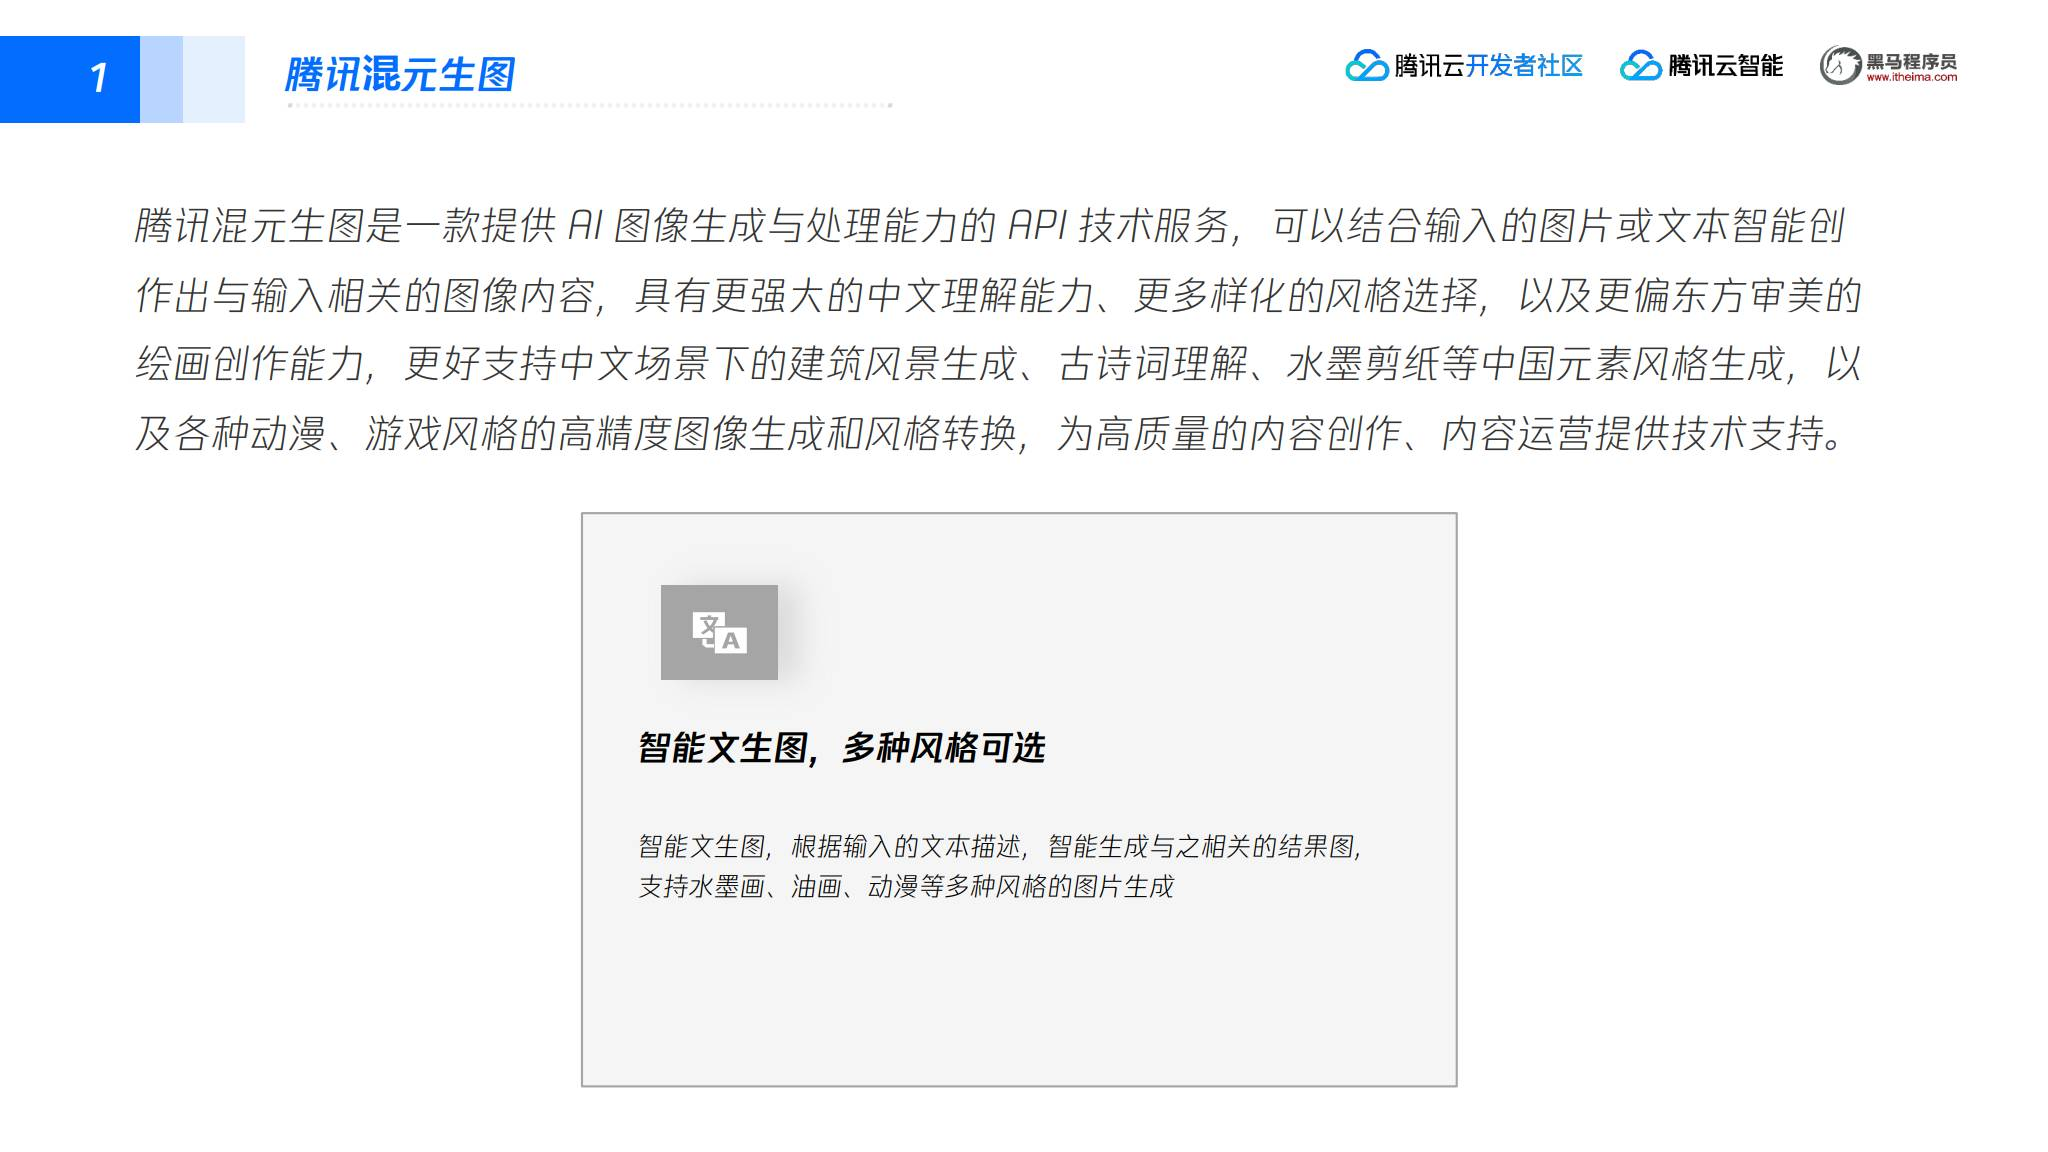

### 1. API 与 SaaS

腾讯混元生图提供两种服务形态：

| 形态 | 使用方式 | 适合人群 |
| --- | --- | --- |
| API | 通过 HTTP 接口或 SDK 调用，程序传入提示词和参数并接收结果 | 有代码基础、了解 HTTP 请求和 API 调用的开发者 |
| SaaS | 直接在网页端输入文字或图片完成创作 | 不需要编程的用户 |

API 适合接入自己的业务，SaaS 适合快速体验和人工创作。

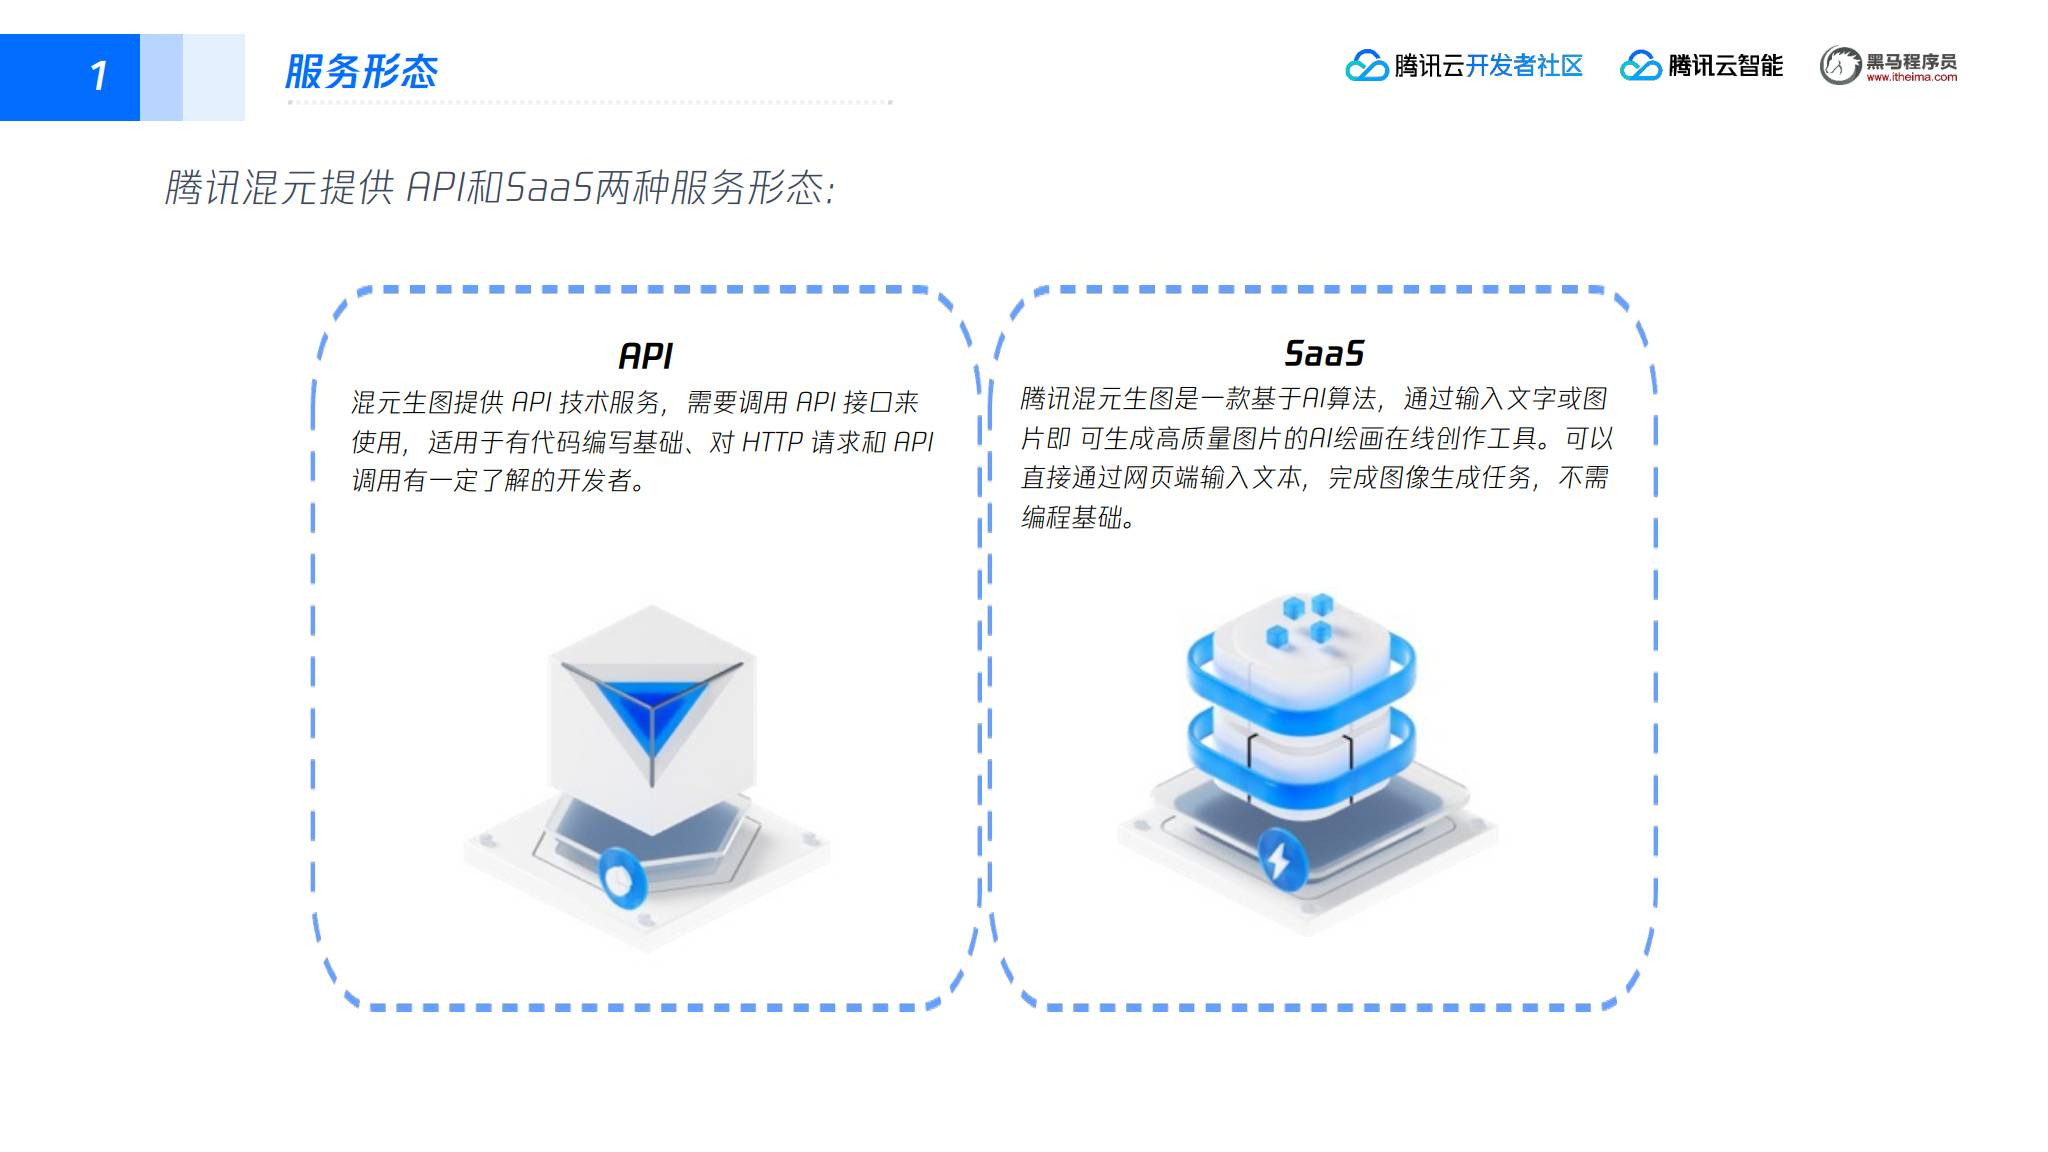

### 2. 产品优势与应用场景

讲义概括的产品优势包括自研算法、风格多样、中文适配性强、配置灵活和性能良好。API 采用标准化接口封装，调用方式相对统一，也便于和业务系统集成。

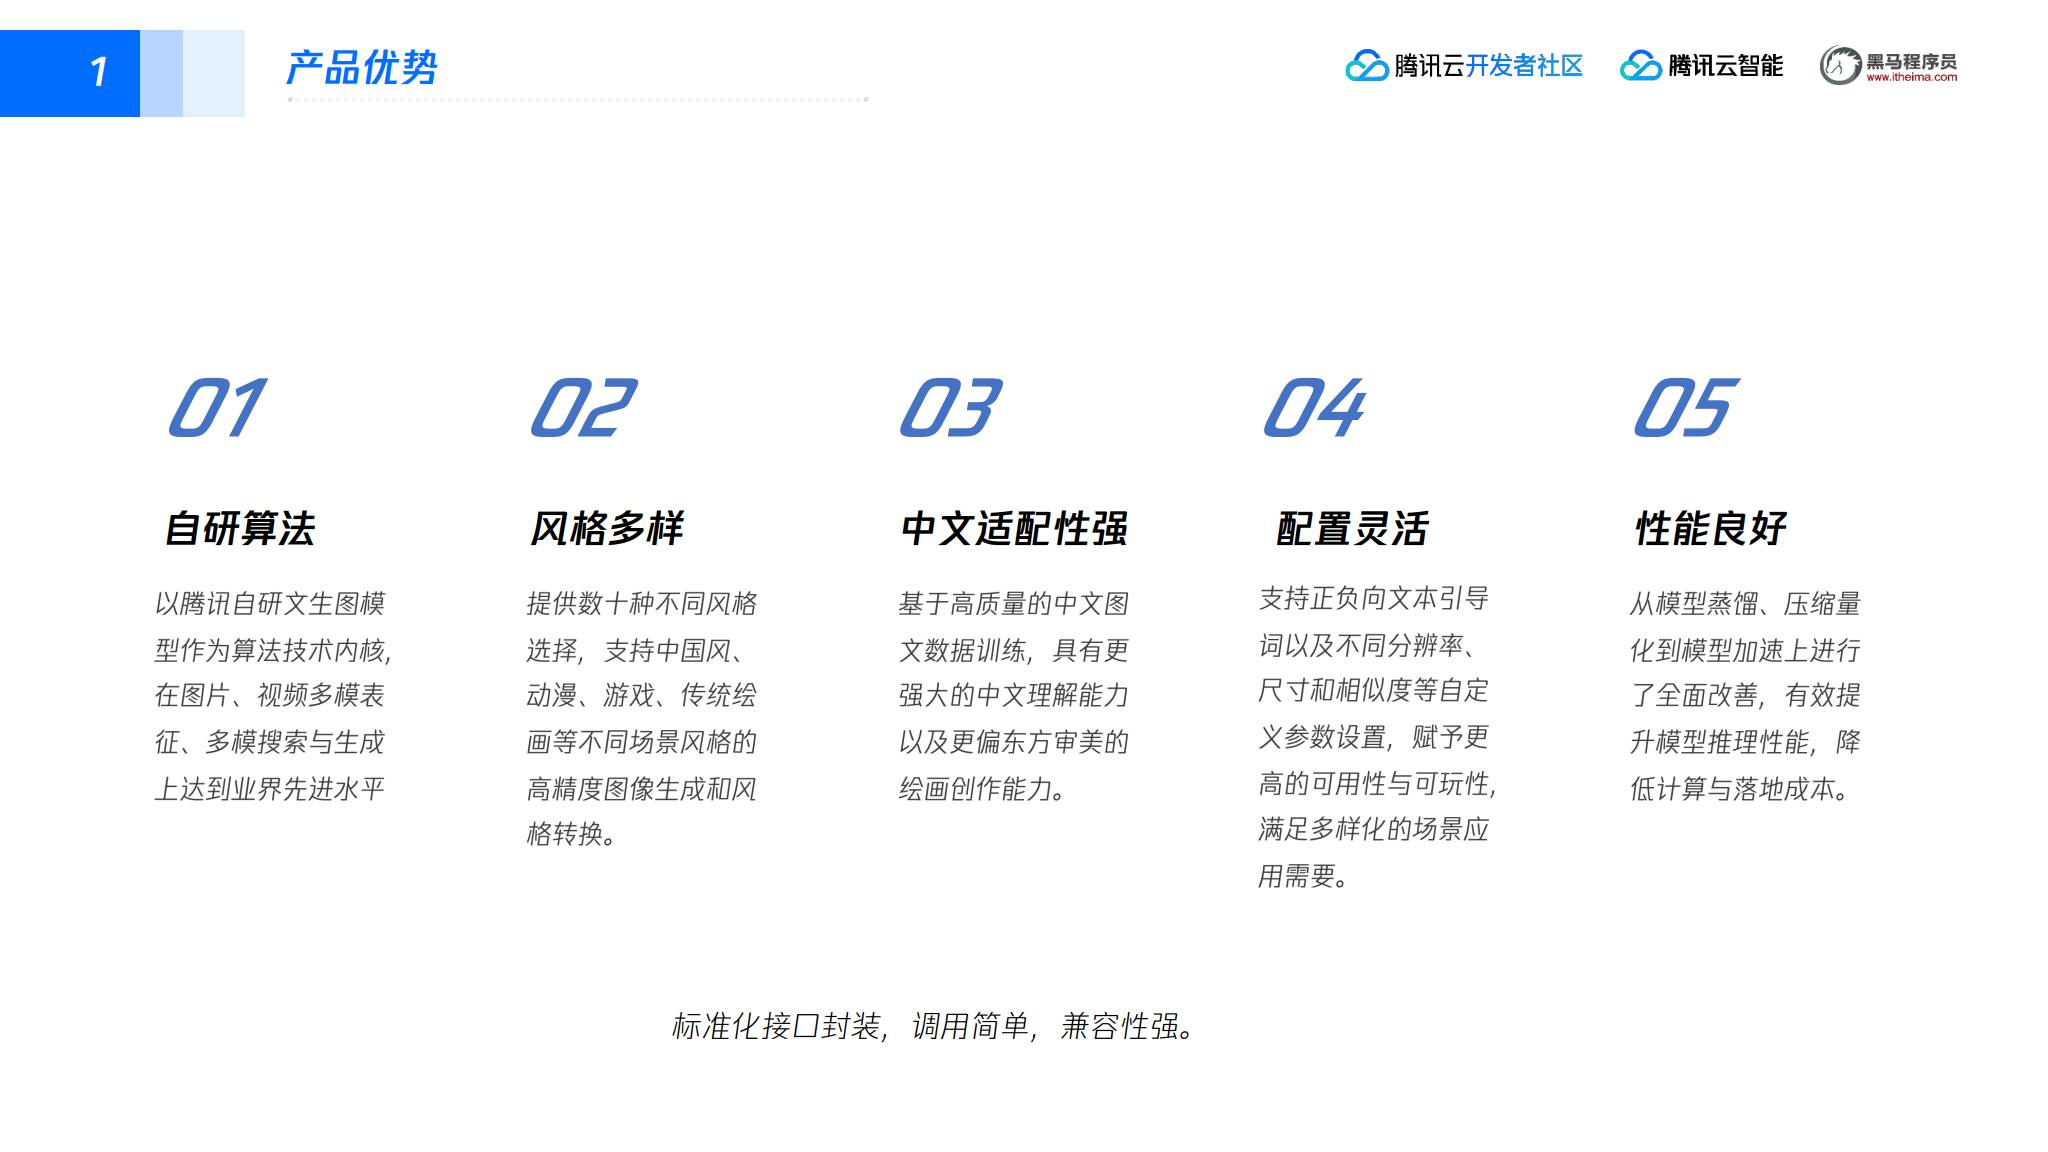

典型应用场景：

- **文化传播**：新年活动、诗意作画、万物皆可剪纸等互动活动；
- **风格变换**：头像风格化、场景风格化；
- **文学配图**：网络小说封面、公众号推文插图；
- **设计辅助**：游戏原画、漫画草图、影视分镜、海报等前期设计。

这些场景的共同点是先用 AI 快速尝试大量构图和风格，再挑选结果进行更高精度的内容创作。

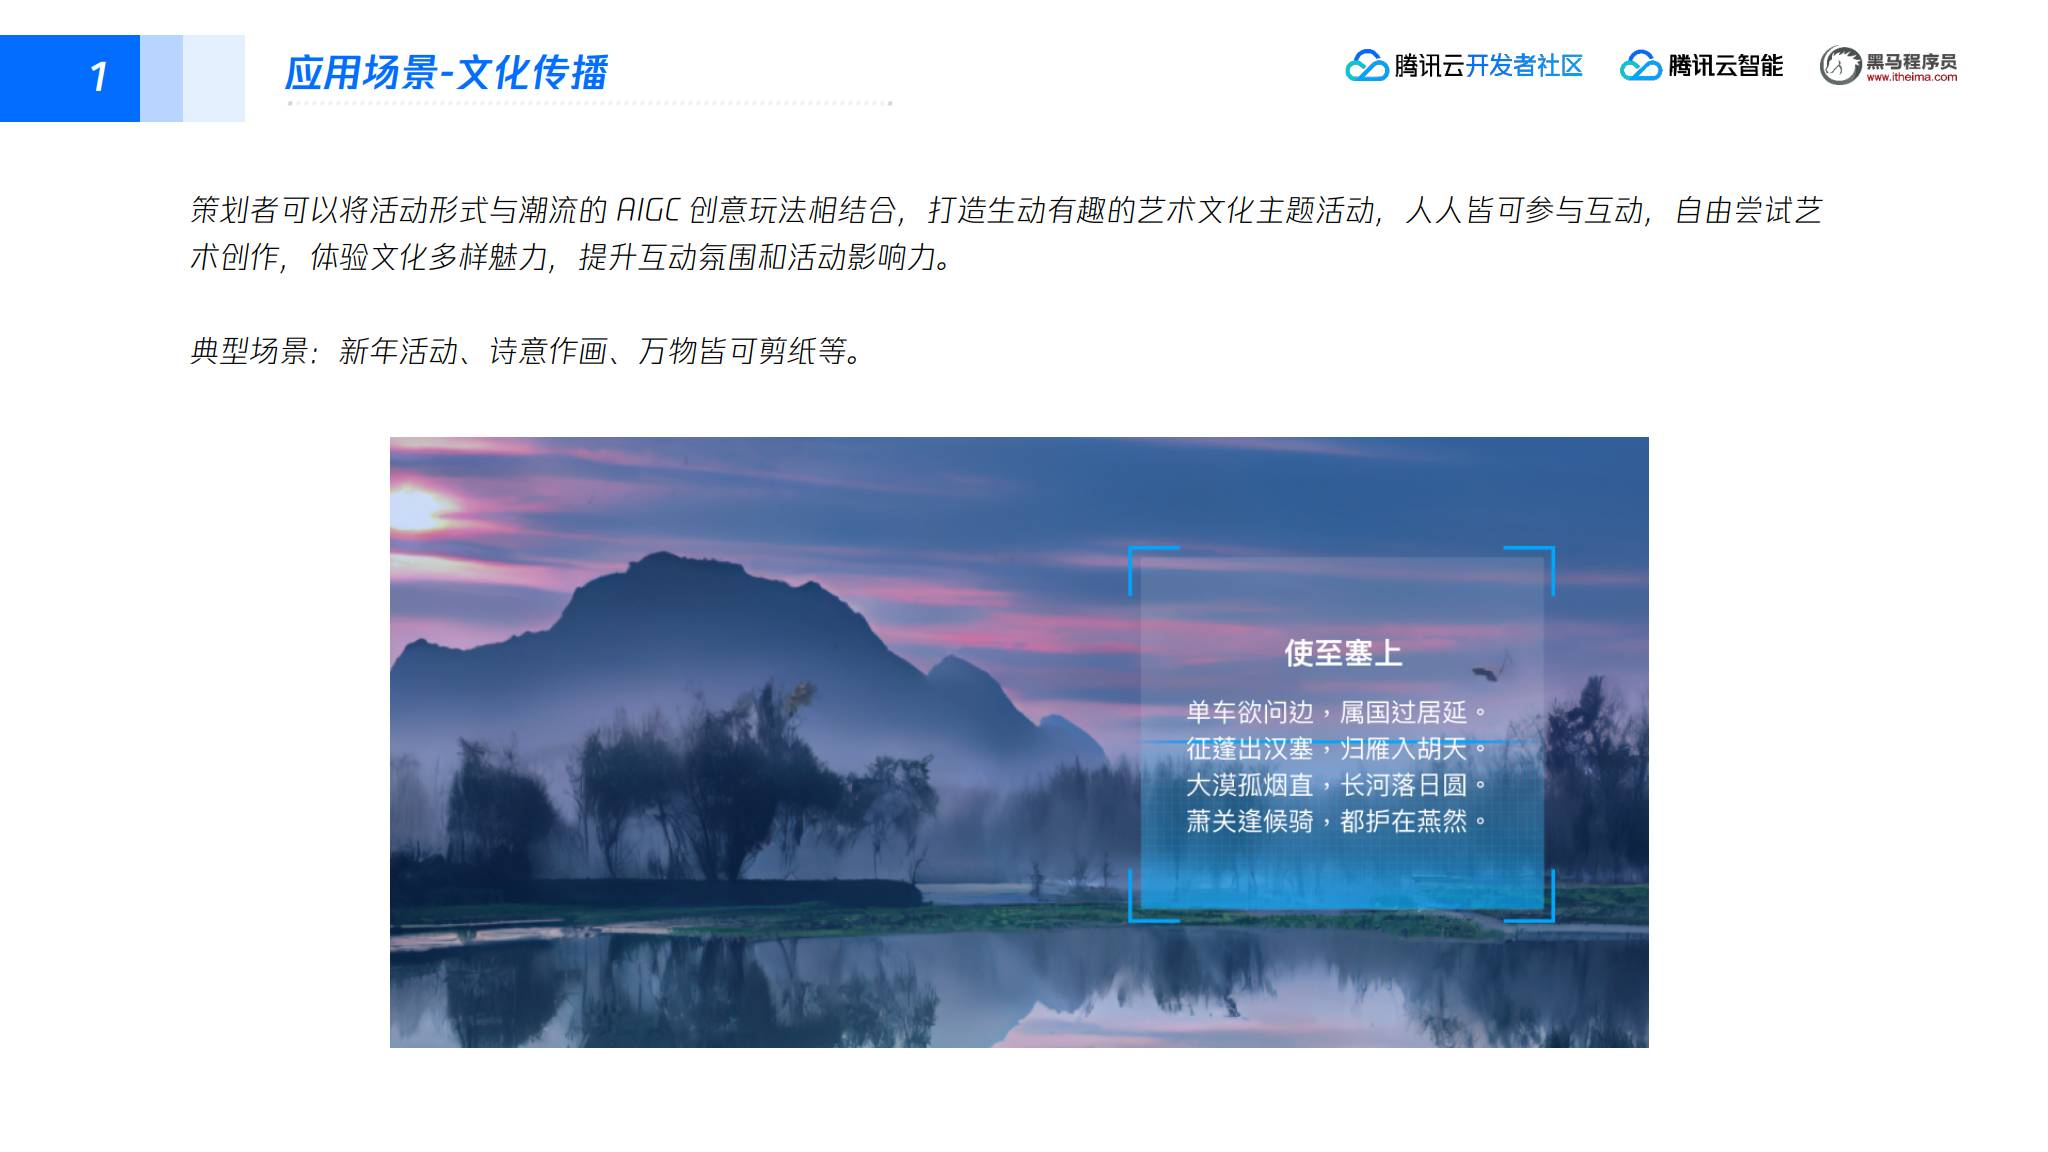

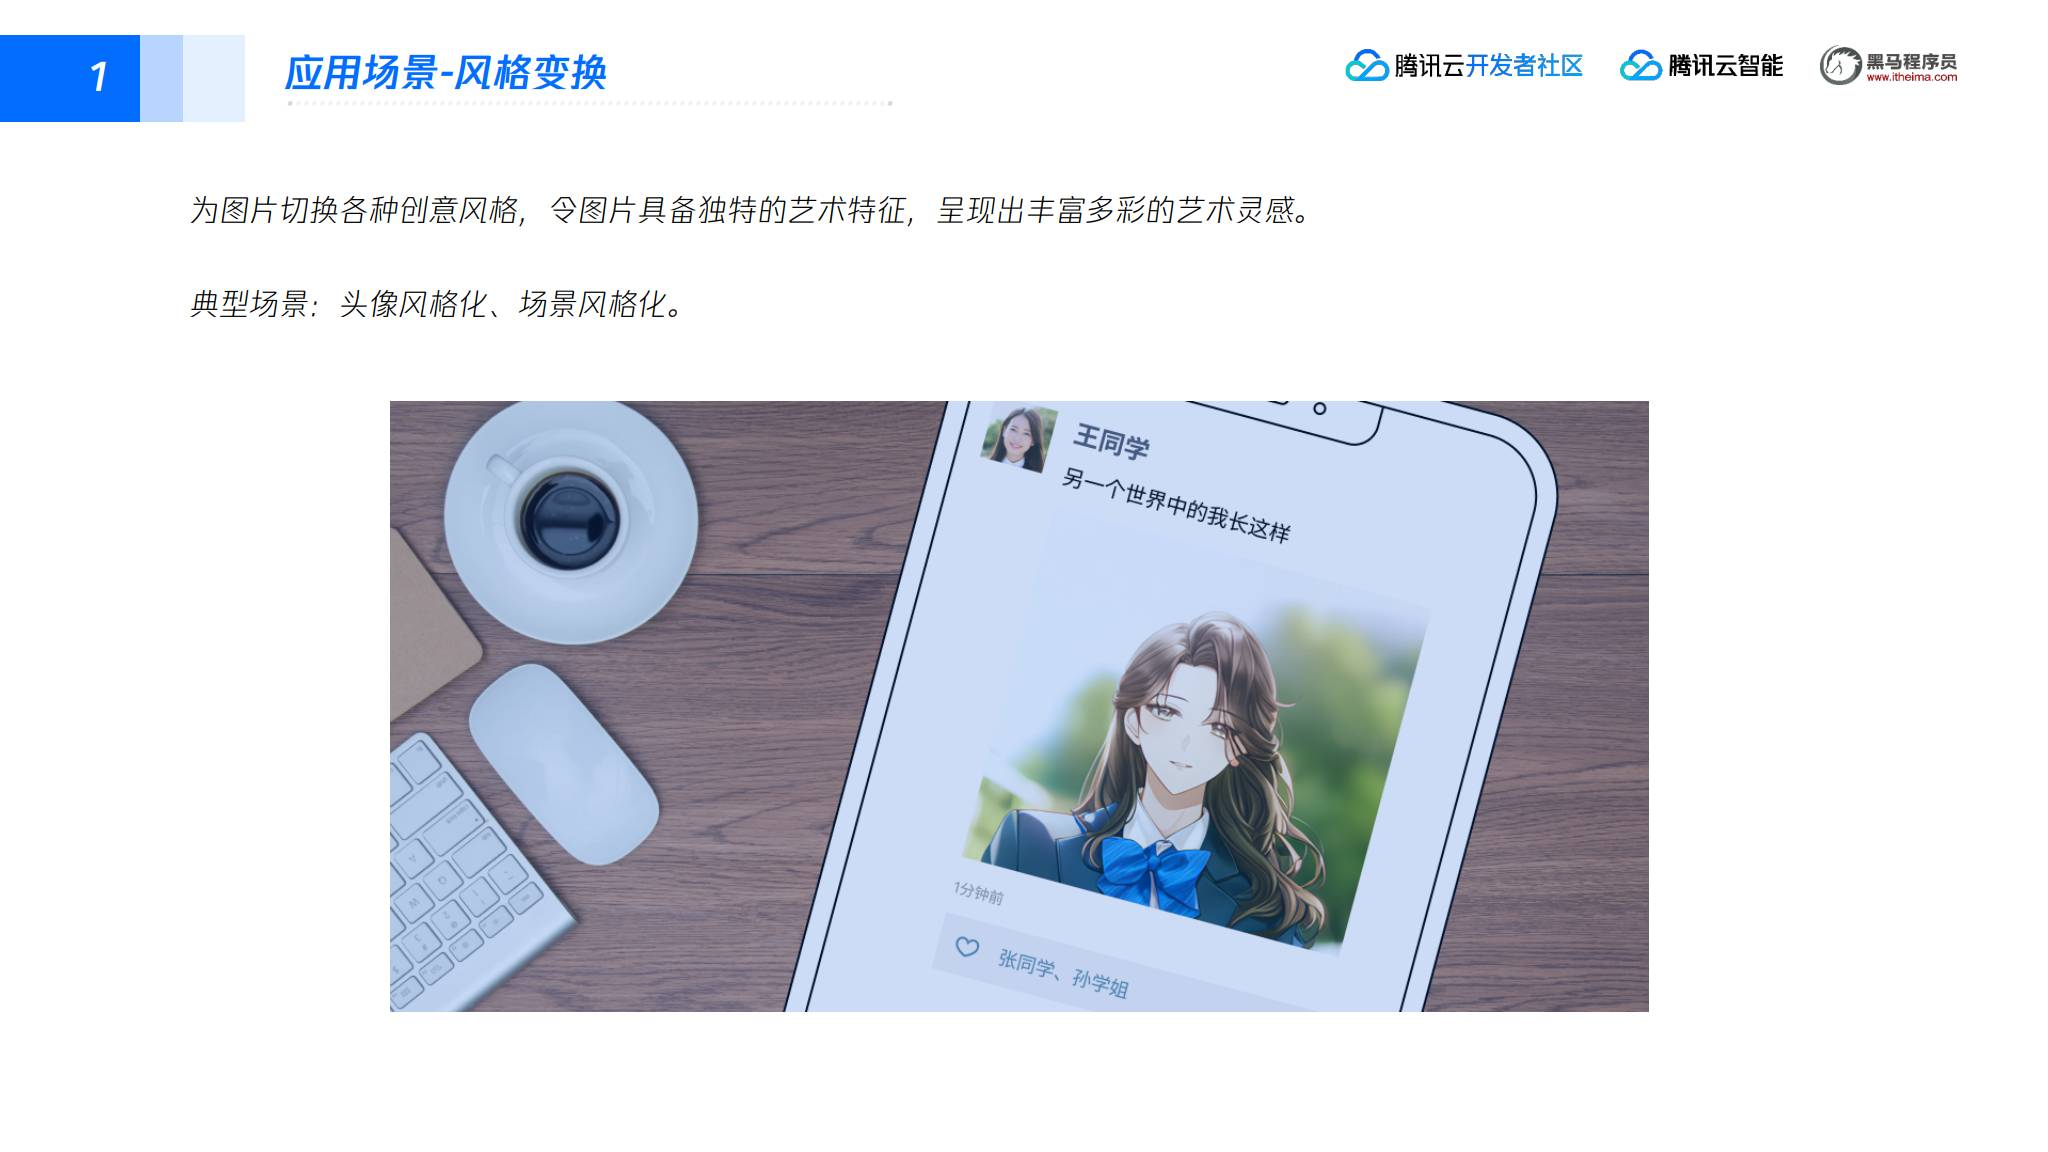

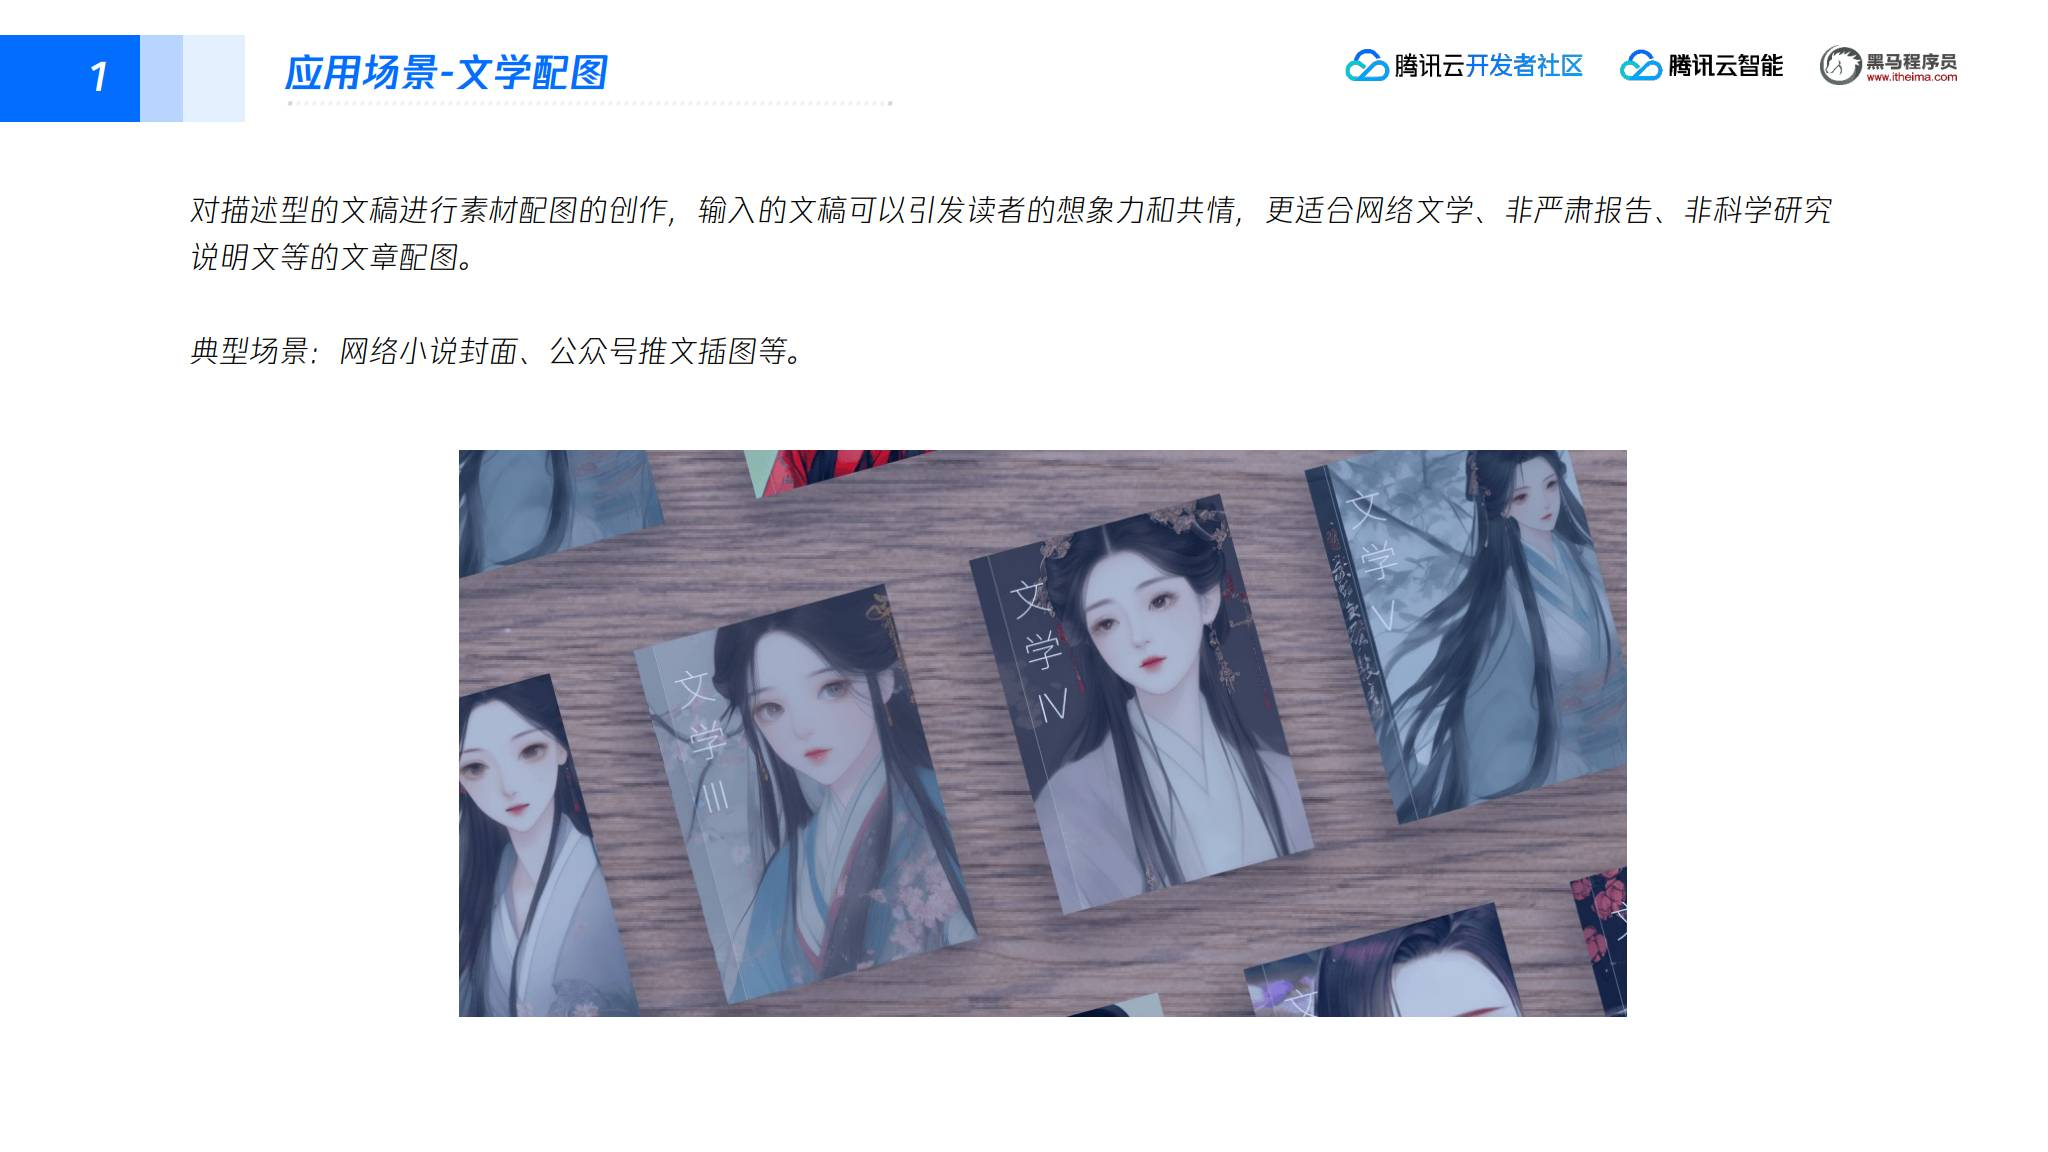

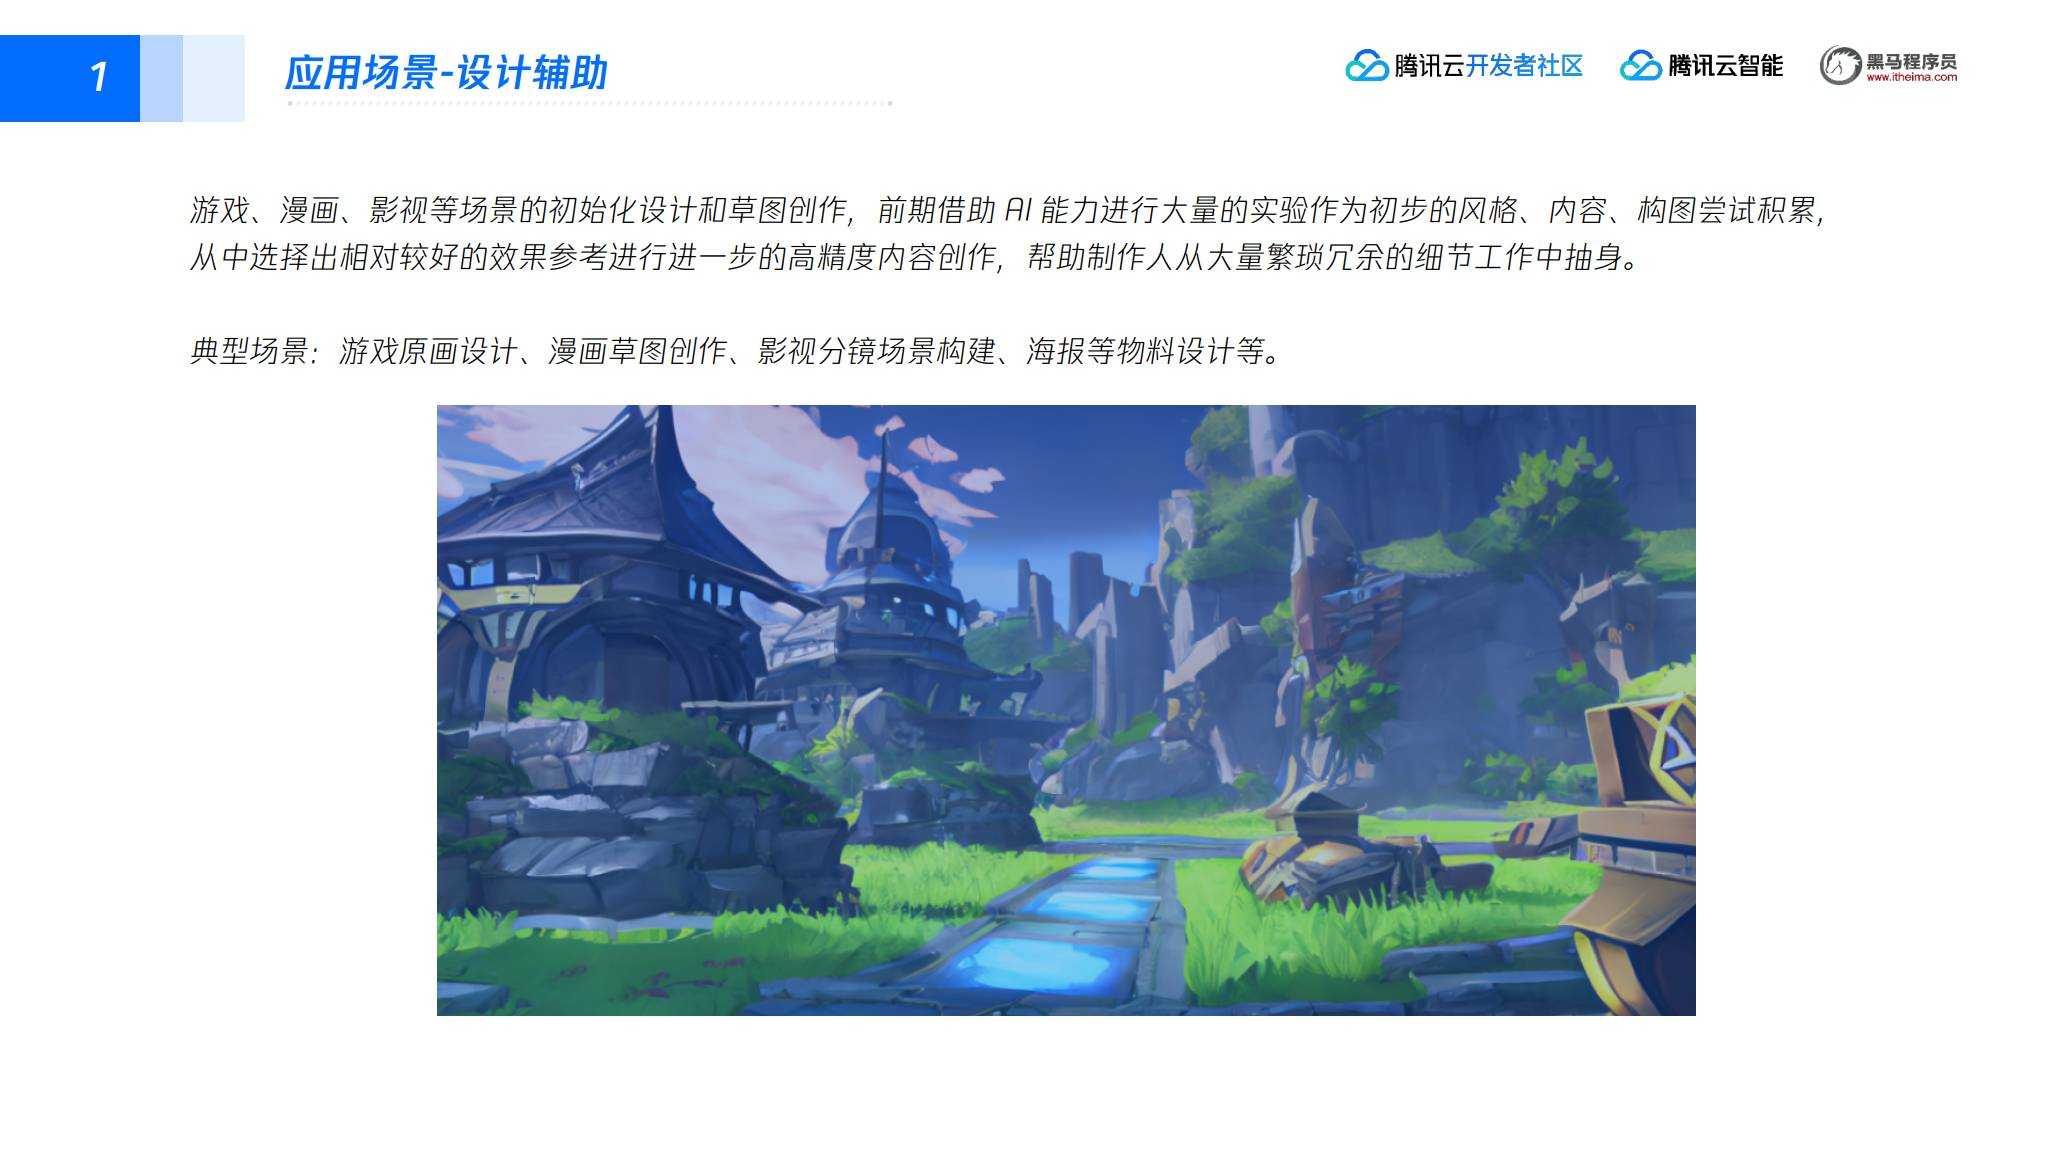

## 二、混元生图 API

### 1. TextToImage 接口

混元生图文生图接口根据输入的描述文本生成相关结果图。讲义给出的约束是：

- 输入：256 个字符以内的描述性文本，推荐使用中文；
- 输出：指定风格和分辨率的 AI 生成图；
- 接口：`TextToImage`，功能为智能文生图；
- 频率限制：课件表格以 `-` 表示，实际额度以腾讯云当前接口文档为准。

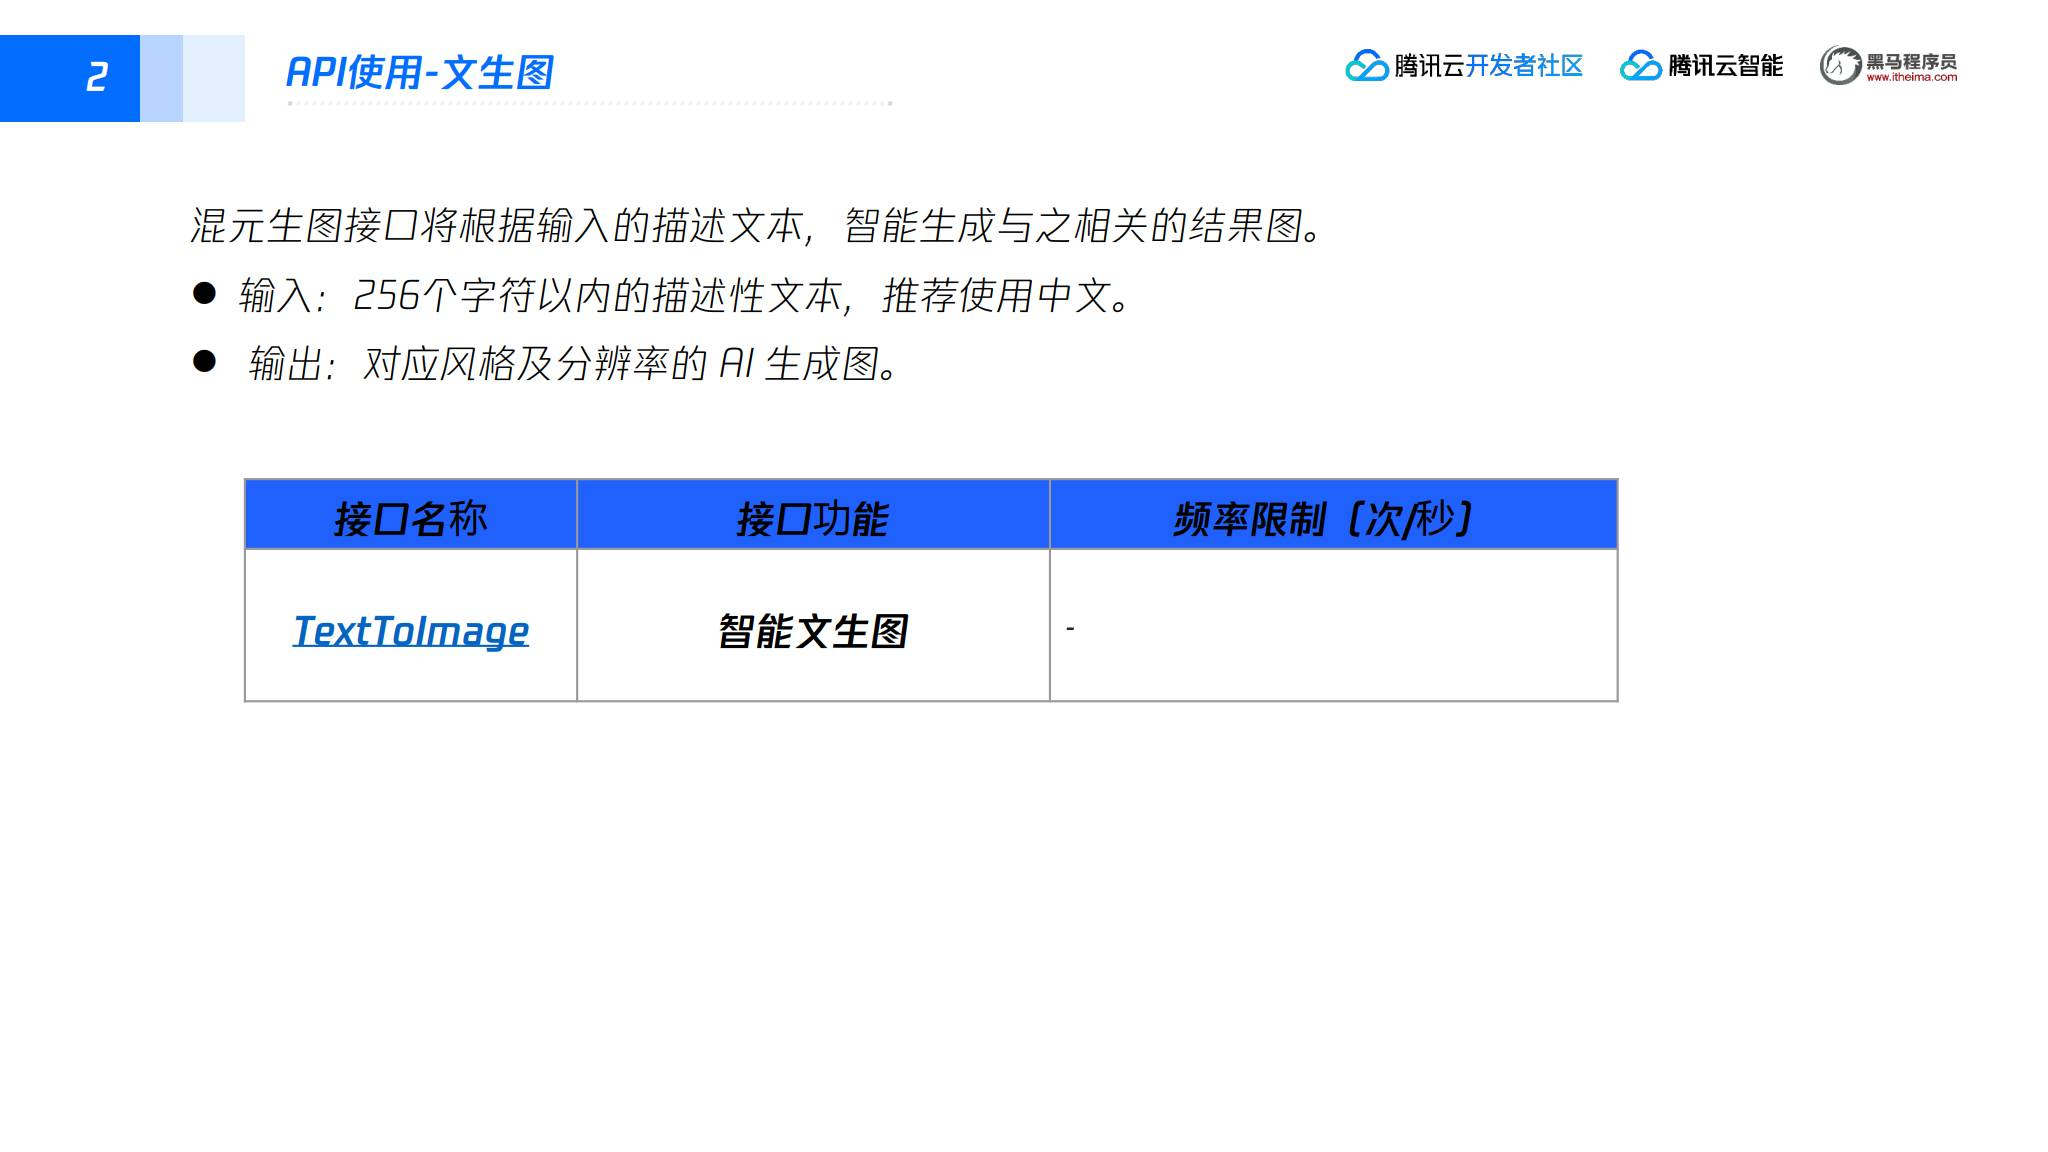

### 2. HTTP 请求与响应

课件示例的 HTTP 请求结构：

```http
POST / HTTP/1.1
Host: ft.tencentcloudapi.com
Content-Type: application/json
X-TC-Action: TextToImage
```

请求体示例只保留业务字段：

```json
{
  "Prompt": "女孩",
  "Styles": ["101"]
}
```

`Prompt` 是描述性提示词，`Styles` 选择绘画风格。课件响应示例包含：

```json
{
  "Response": {
    "ResultImage": "<图片数据或图片信息>",
    "RequestId": "<请求标识>"
  }
}
```

不要把课件截图中的账号密钥复制到代码中；调用腾讯云时应使用环境变量、密钥管理服务或 SDK 推荐的安全凭证方式。

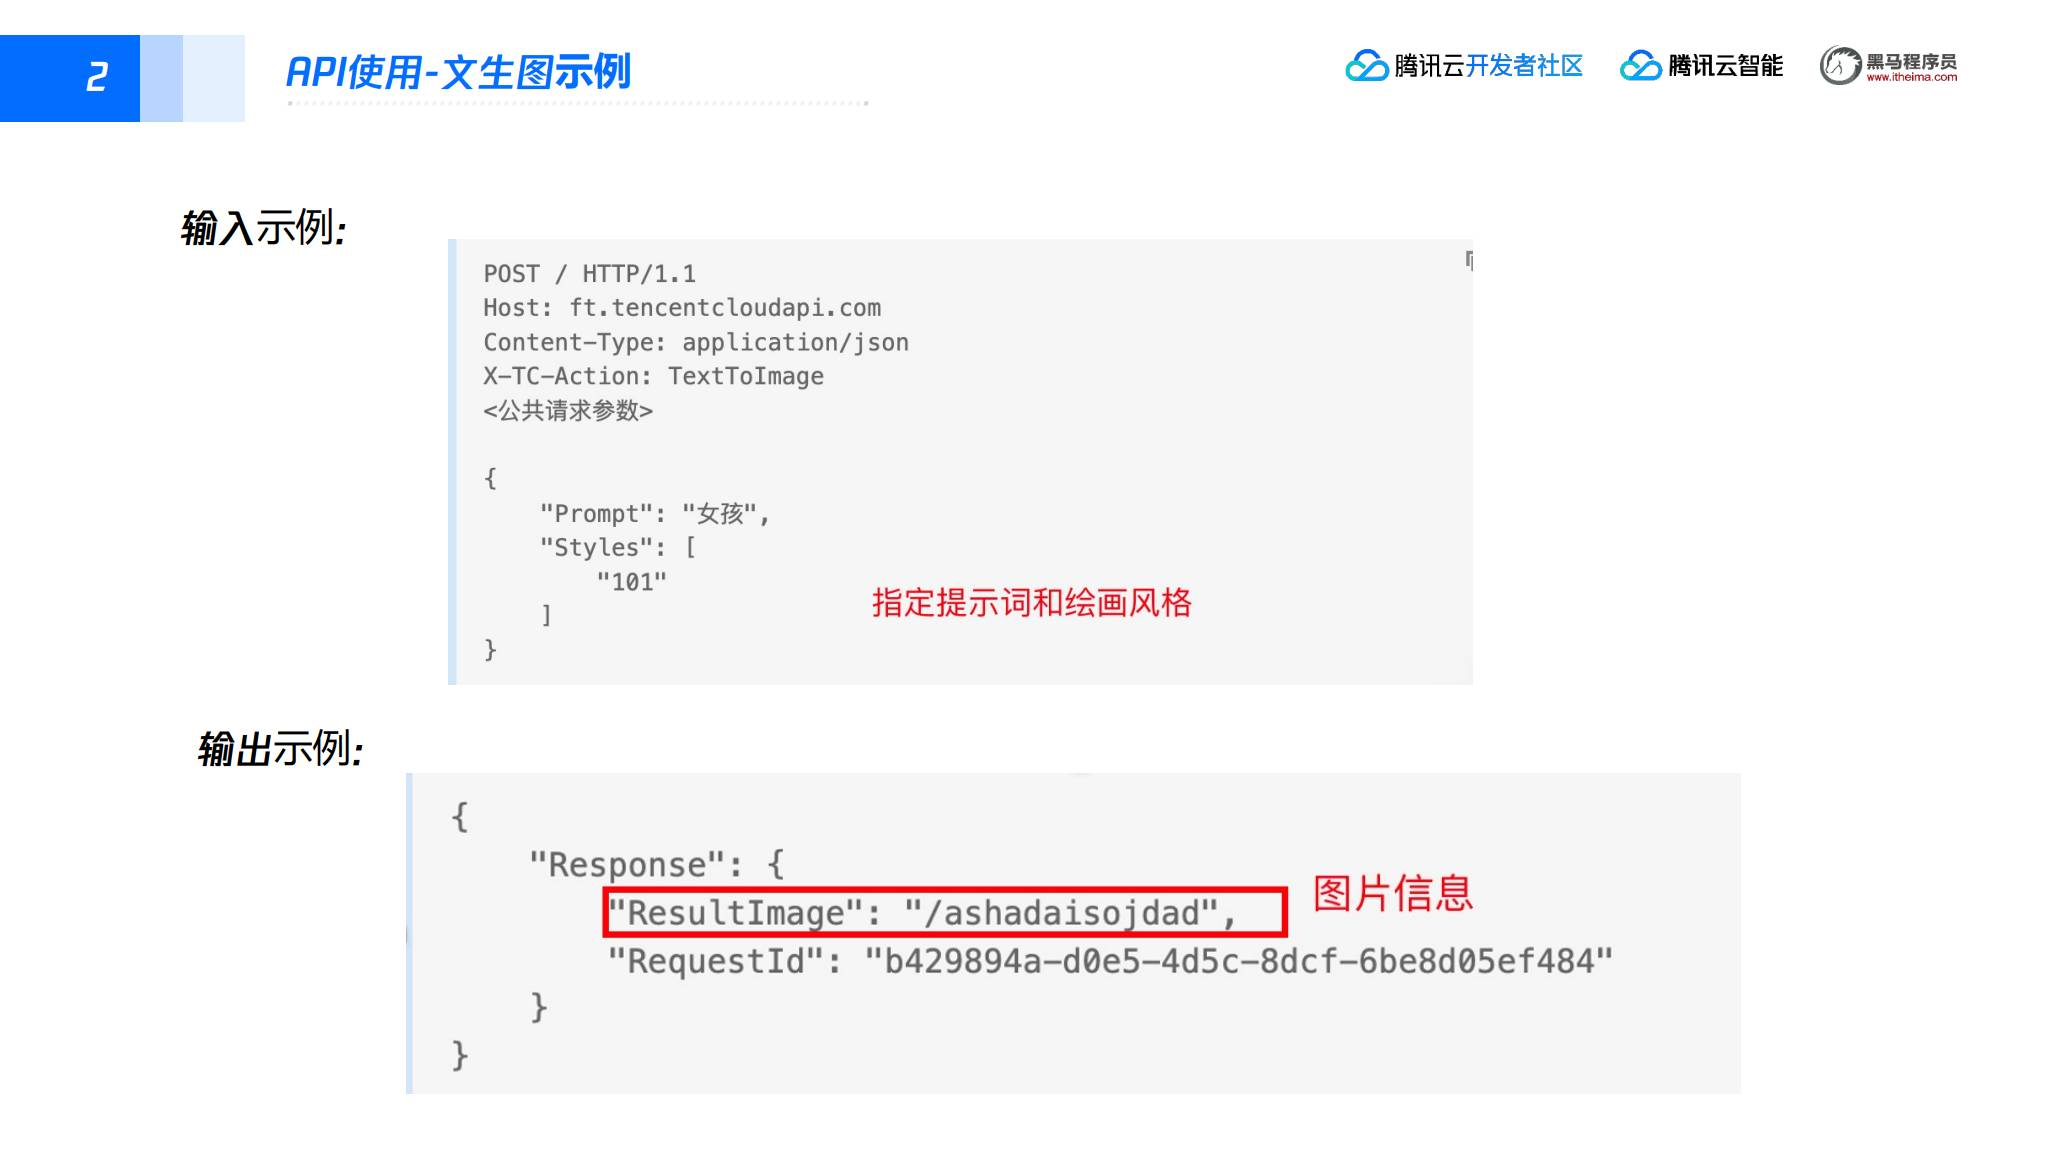

### 3. API Explorer

讲义使用 API Explorer 演示接口调用：

1. 在接口列表中选择腾讯混元生图；
2. 选择“混元生图（2.0）”相关接口；
3. 选择地域，例如截图中的华南地区 `ap-guangzhou`；
4. 在表单或 JSON 中填写 `Prompt`、`NegativePrompt`、`Styles.N`、`ResultConfig.Resolution` 和 `LogoAdd` 等参数；
5. 选择“代码生成”查看 Go、Python、Java 等示例，或选择“在线调用”直接查看生成图。

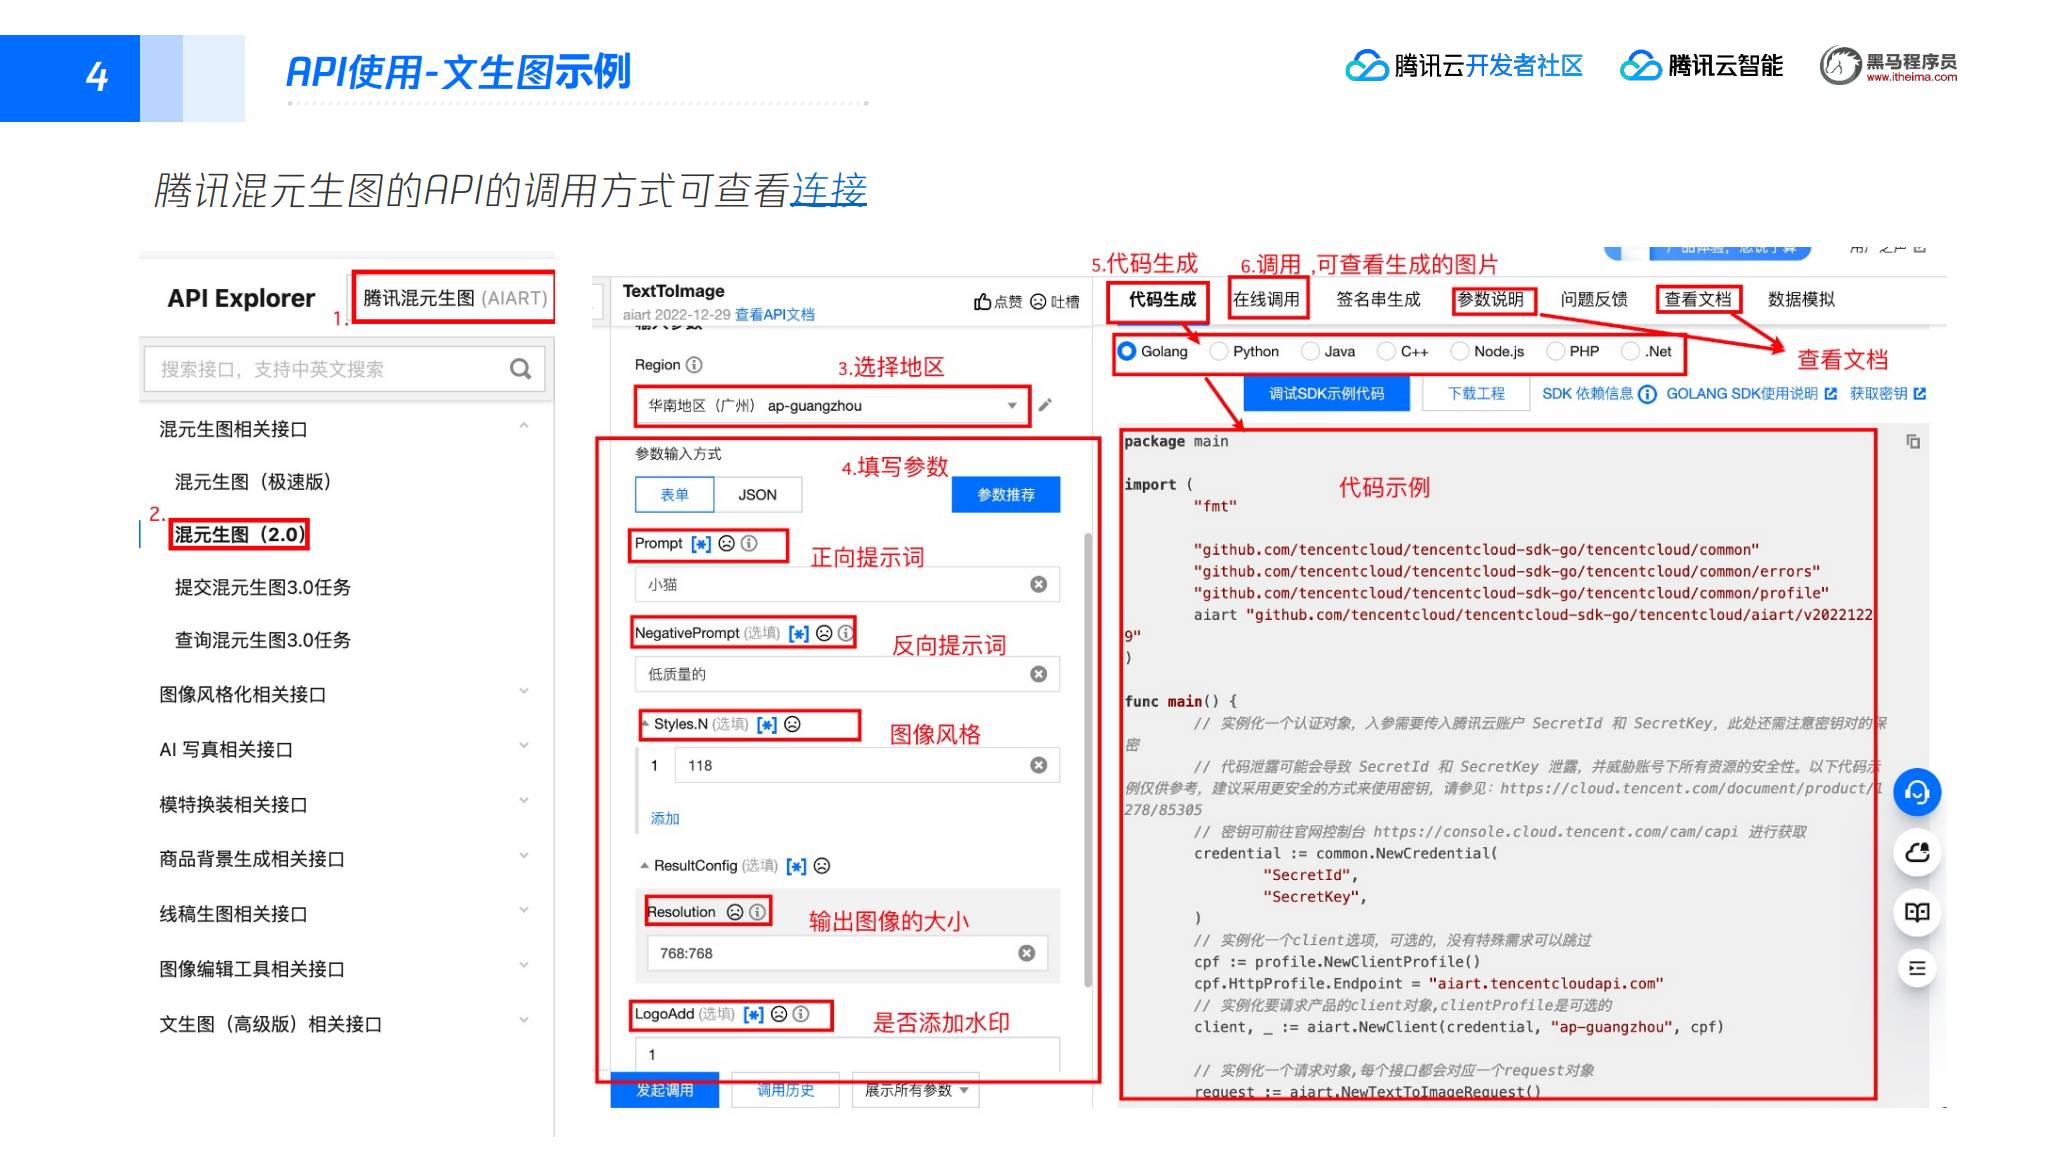

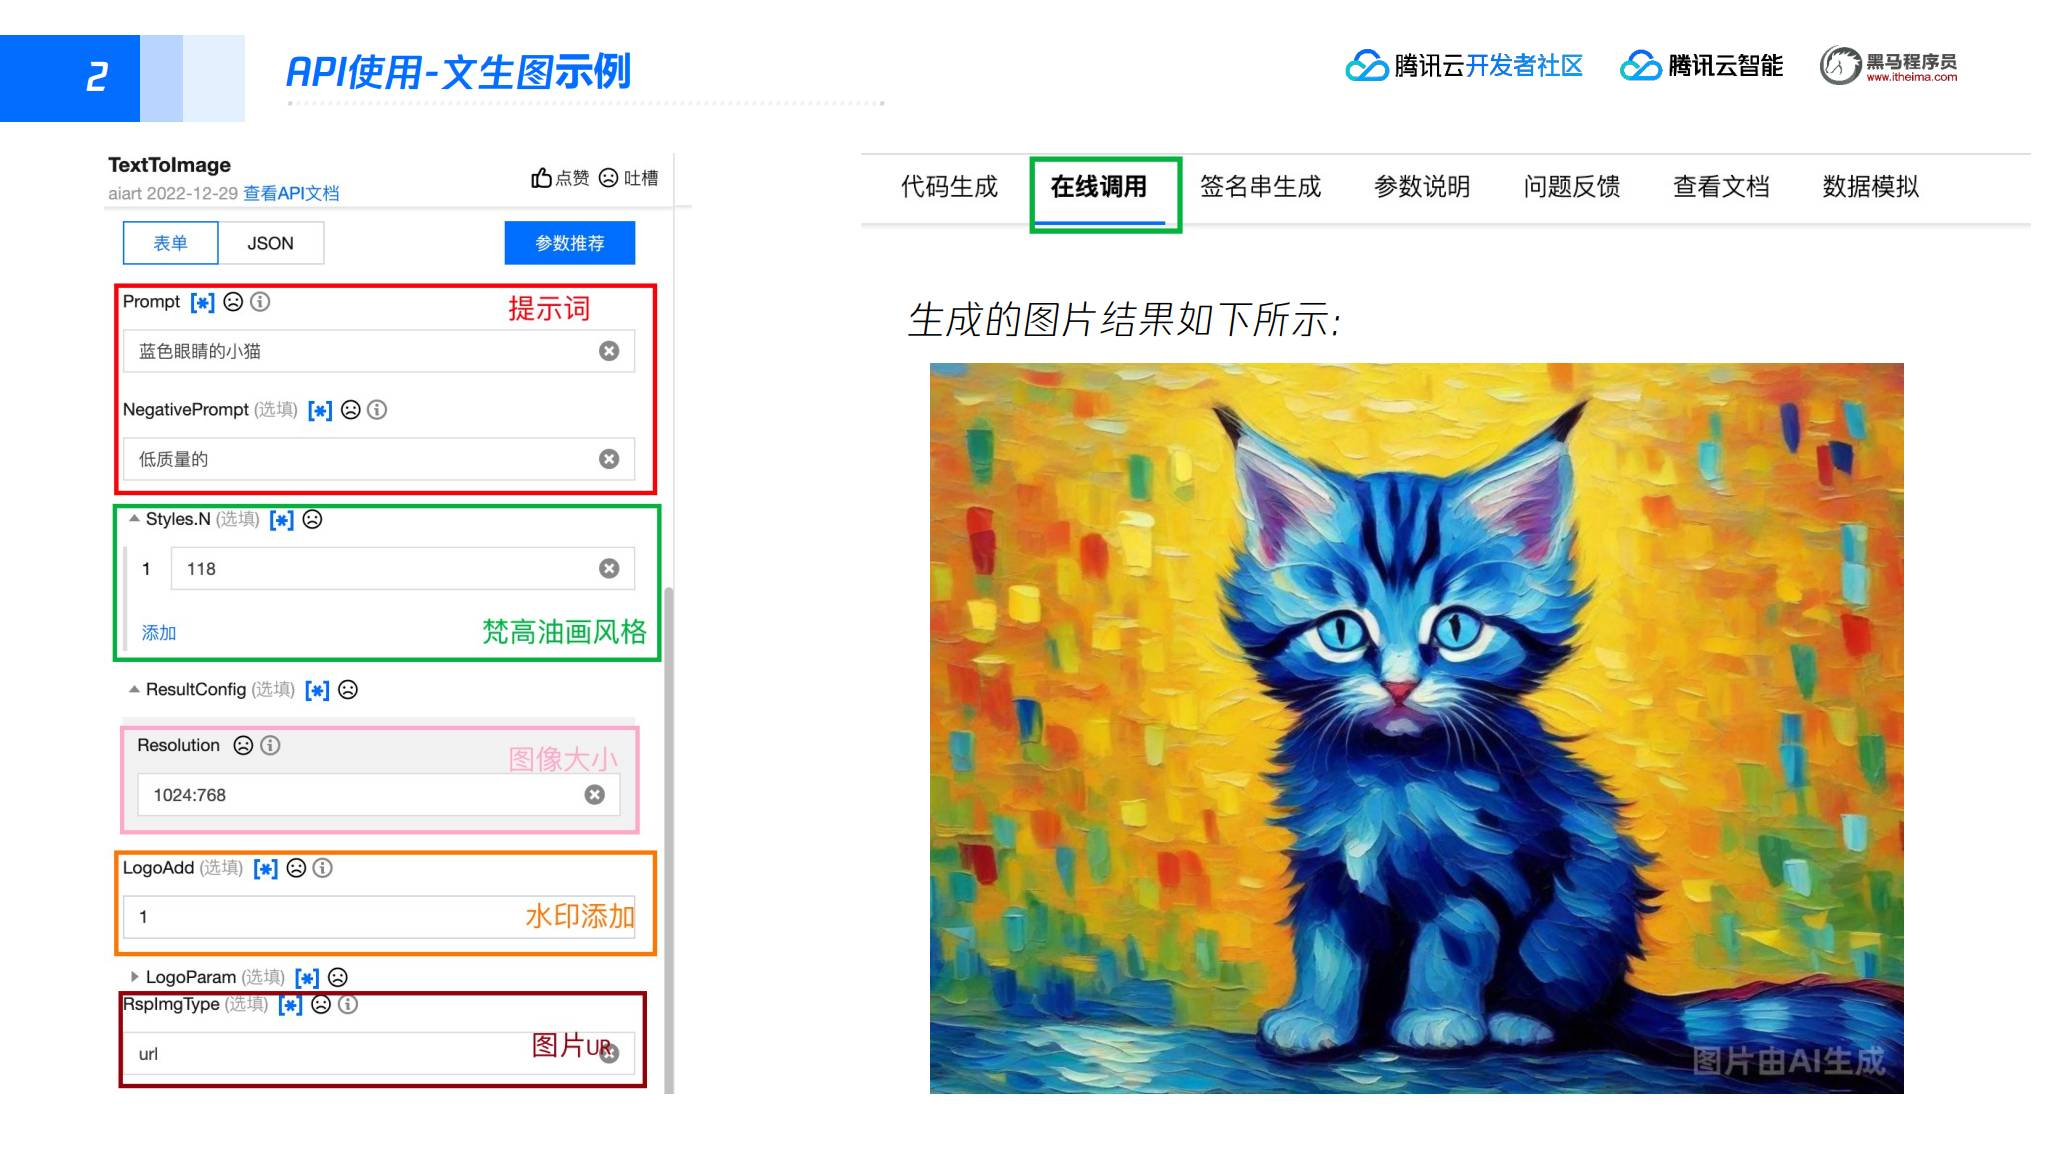

> 课程截图中的具体参数和接口版本属于讲义当时的控制台页面。实际开发前应以腾讯云当前 API 文档、地域和账号权限为准。

## 三、腾讯混元生图 SaaS

腾讯混元生图也提供在线创作工具，核心功能是输入文字或图片生成高质量图片，不需要编程基础。课程给出的产品入口是：

[腾讯混元生图控制台](https://console.cloud.tencent.com/aiart/hunyuan-image-create)

基本使用流程是：

1. 打开网页并进入在线创作；
2. 输入提示词或上传图片；
3. 选择需要的风格和生成参数；
4. 发起生成；
5. 对满意的作品下载并保存到本地。

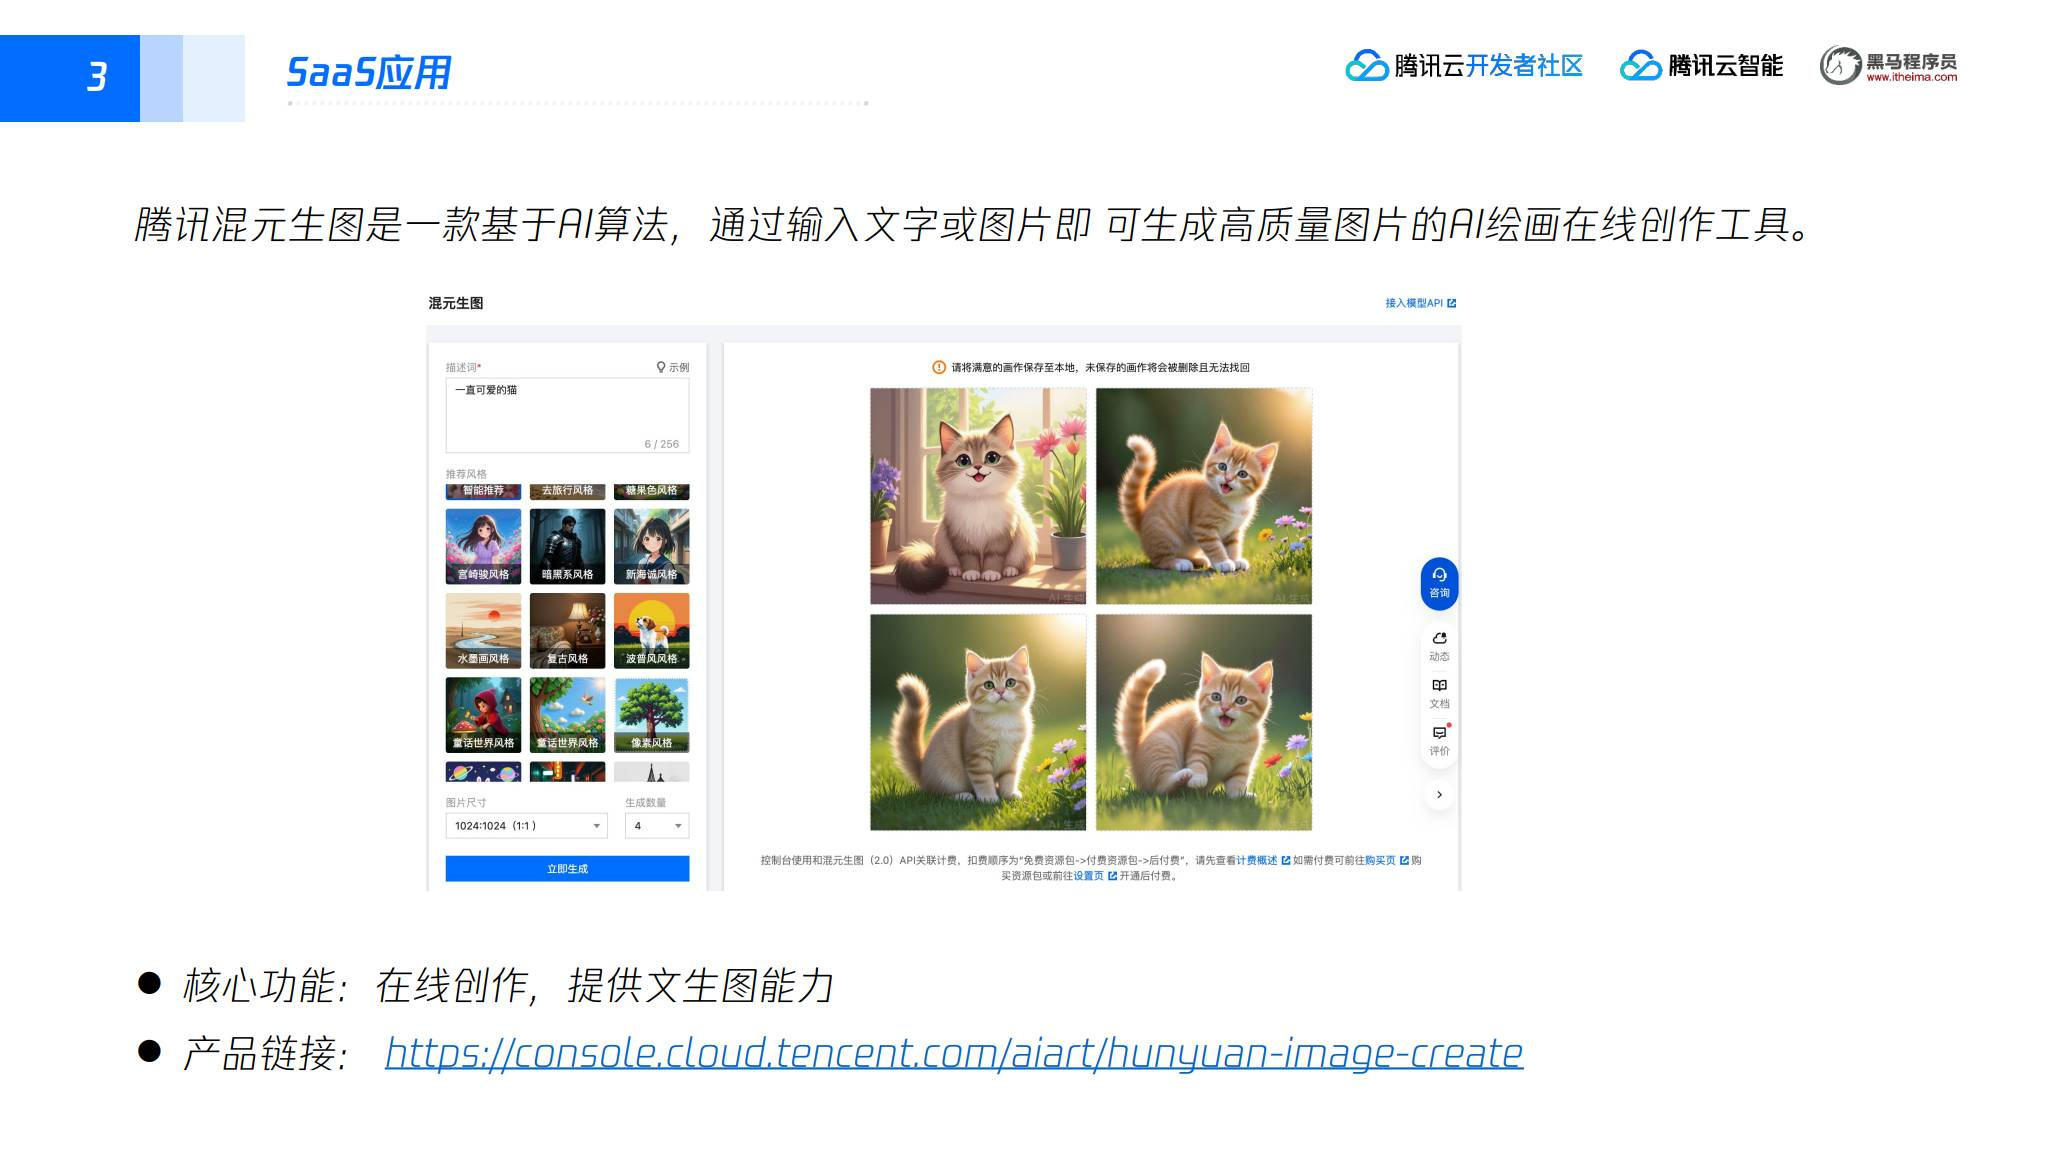

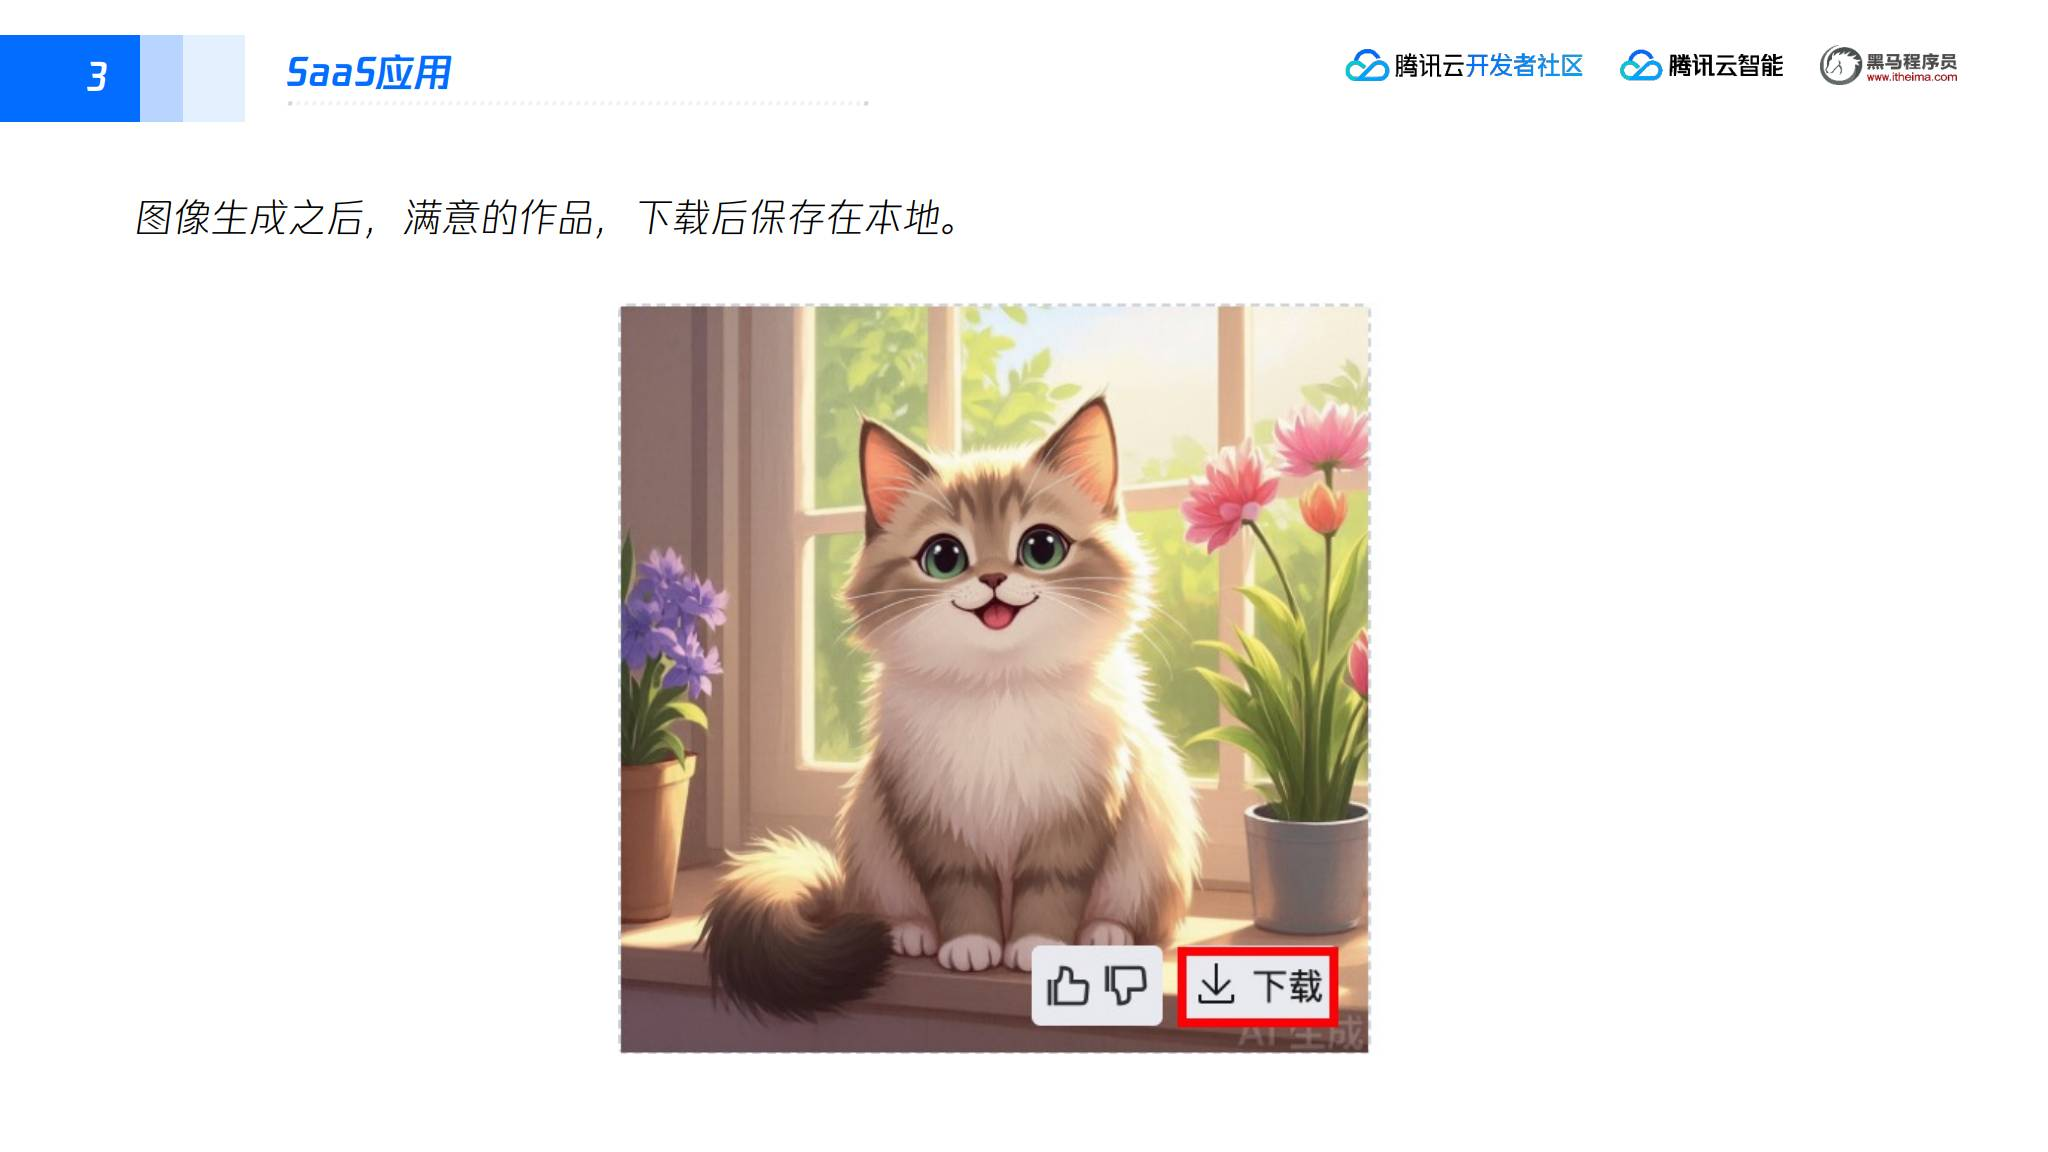

## 四、小程序 AI 绘画最佳实践

### 1. 整体实现思路

小程序实践不是让前端直接保存腾讯云密钥，而是增加一个服务端中转层：

1. 小程序提交用户提示词；
2. 服务端创建任务并把任务信息写入 COS；
3. 绘画服务从 COS 拉取任务，调用腾讯混元生图 API；
4. 生成的图片先保存到服务端，再上传到 COS；
5. 服务端把任务状态、结果地址和耗时返回给小程序；
6. 小程序轮询或查询任务，展示进度和最终图片。

COS 在这里同时承担任务队列、任务结果存储和图片对象存储的作用。

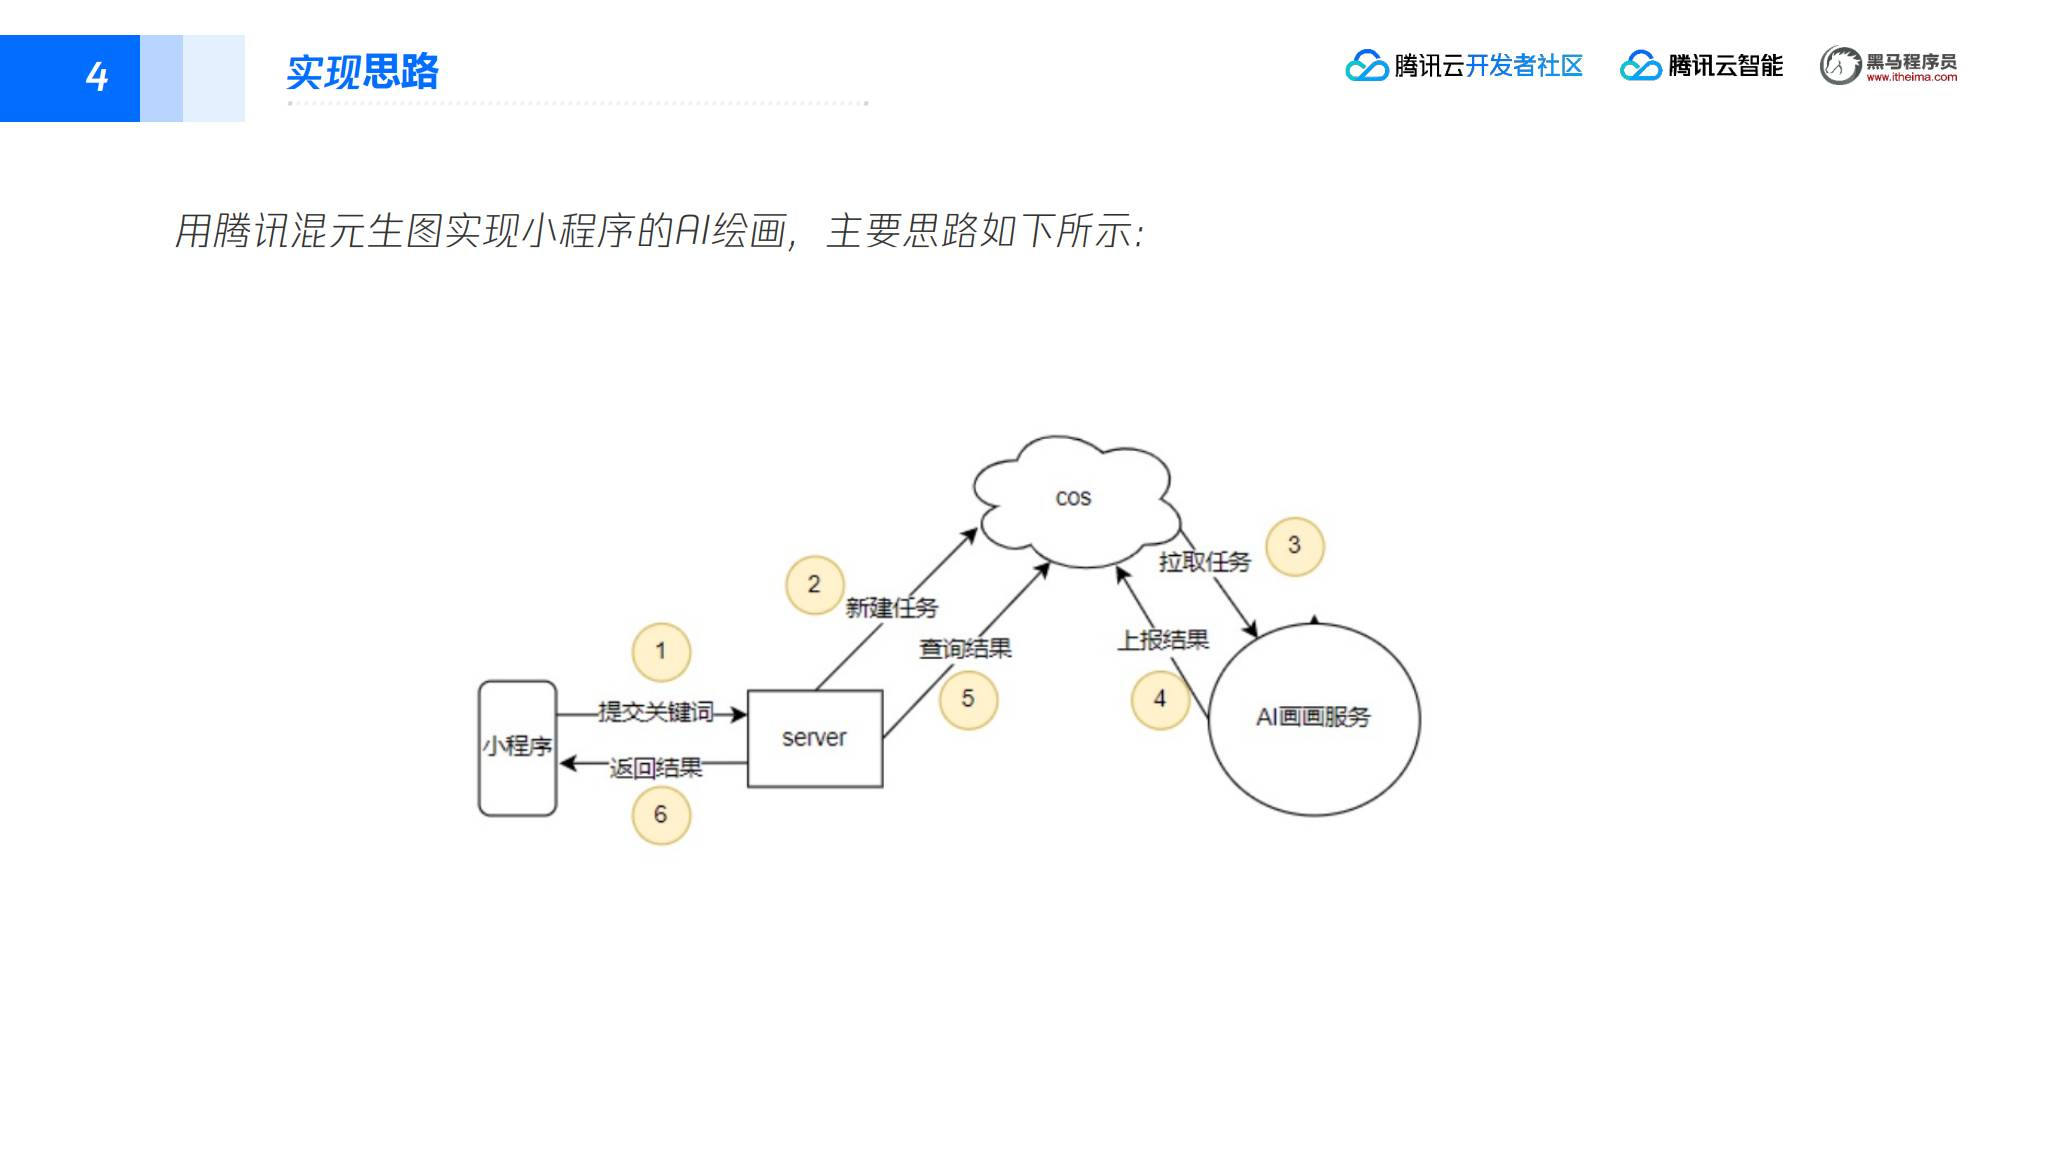

### 2. 项目目录

课件目录分为小程序端和 Go 服务端：

```text
aigc_demo/
├── aidraw/                 # 小程序端
│   ├── app.js
│   ├── app.json
│   ├── app.wxss
│   ├── pages/
│   ├── utils/
│   ├── project.config.json
│   ├── project.private.config.json
│   └── sitemap.json
└── drawserver/             # 服务端
    ├── cloud.go            # 腾讯云调用
    ├── config/             # 配置
    ├── cos/                # COS 操作
    ├── draw.go             # 调用混元生图接口
    ├── job.go              # 任务管理
    ├── main.go             # HTTP 服务
    └── output/             # 生成图片
```

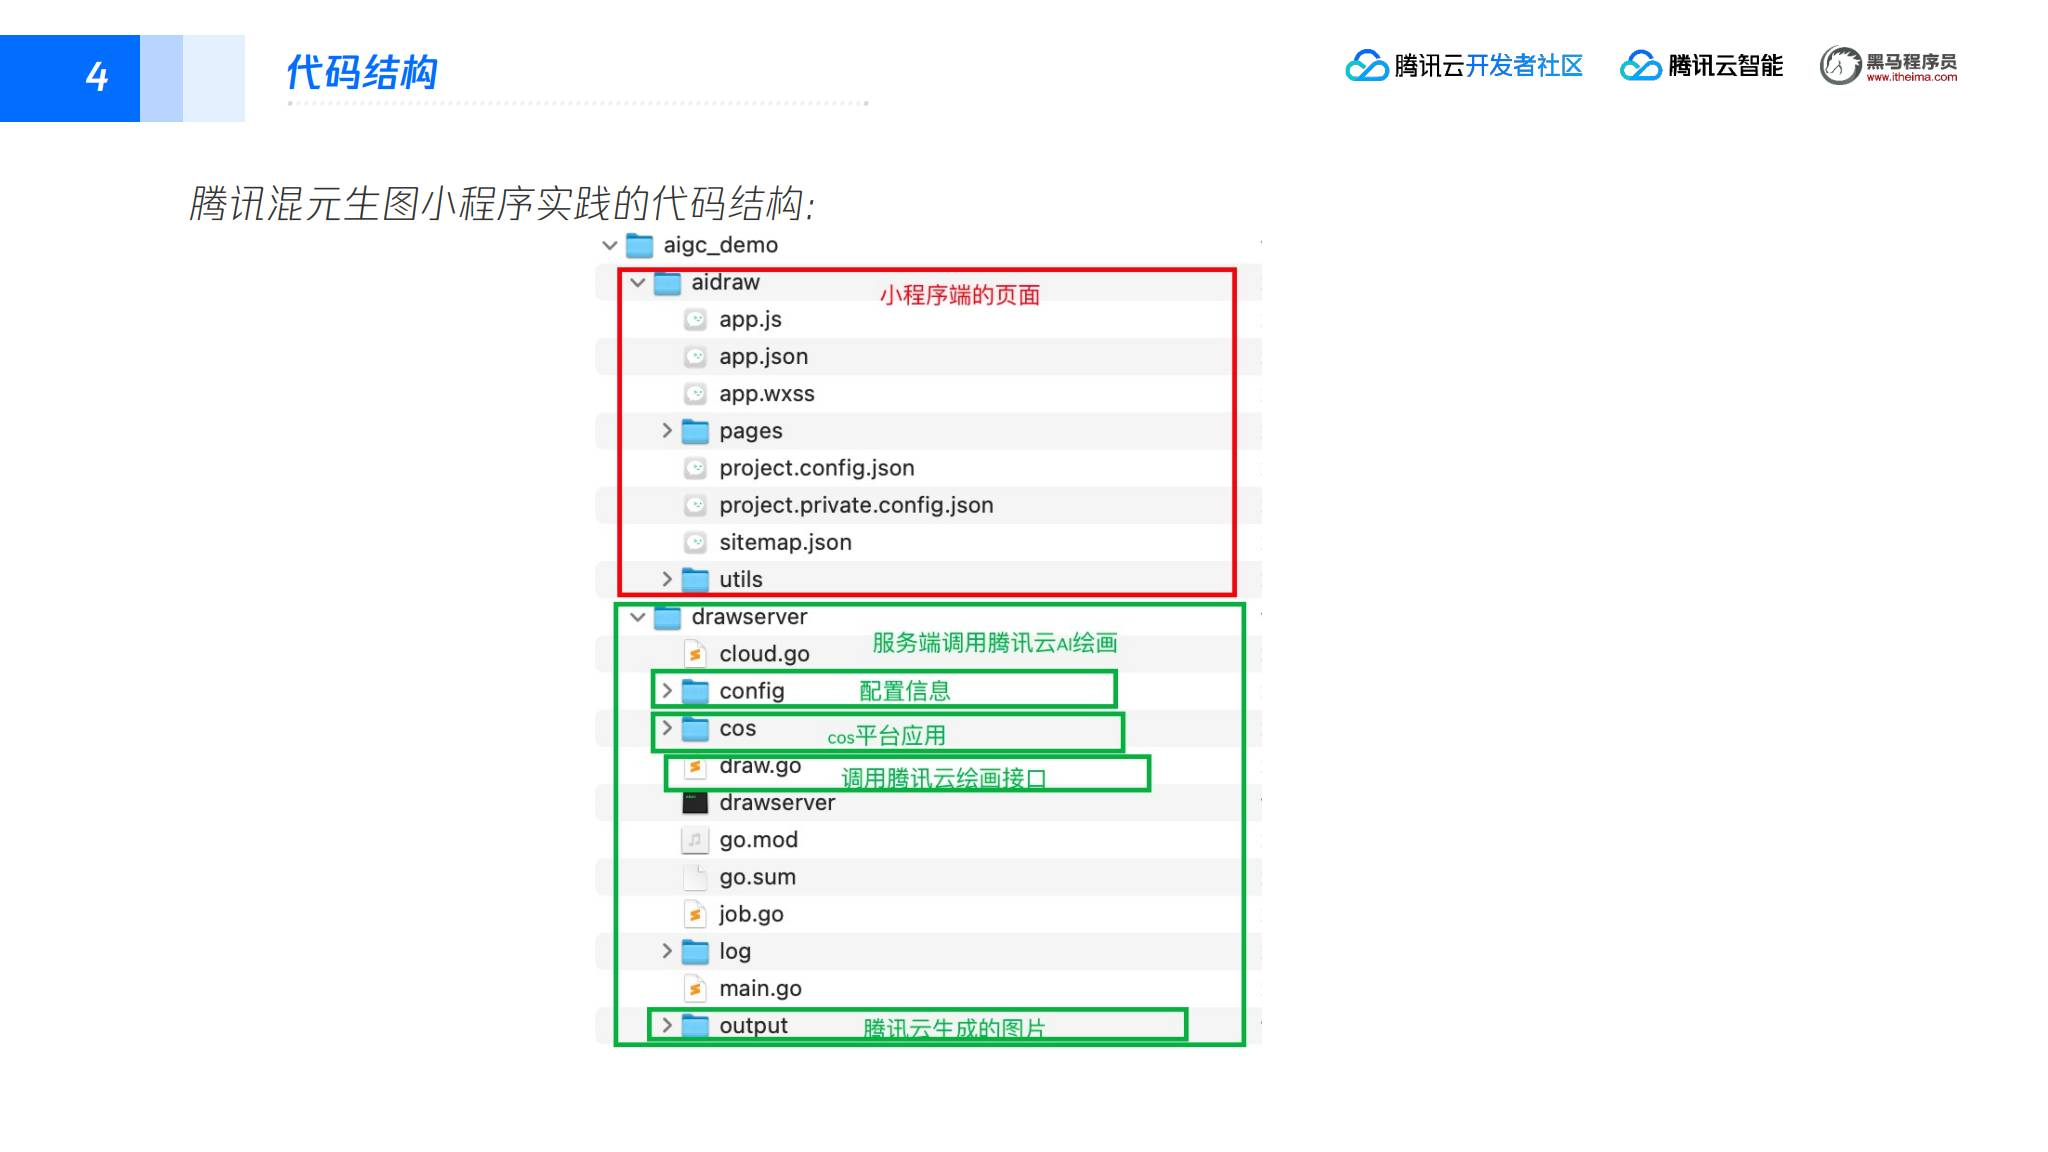

### 3. Go 调用混元生图 API

课件中的 Go 代码流程是：

1. 从请求中读取任务信息和 prompt；
2. 用腾讯云凭证创建客户端；
3. 设置 endpoint `aiart.tencentcloudapi.com` 和地域 `ap-guangzhou`；
4. 创建 `TextToImageRequest`；
5. 设置 `ResultConfig.Resolution`、`RspImgType` 和 `Prompt`；
6. 调用 `client.TextToImage(request)`；
7. 读取响应中的 `Response.ResultImage`；
8. 对 base64 图片数据解码并保存到 `output/<jobId>.png`。

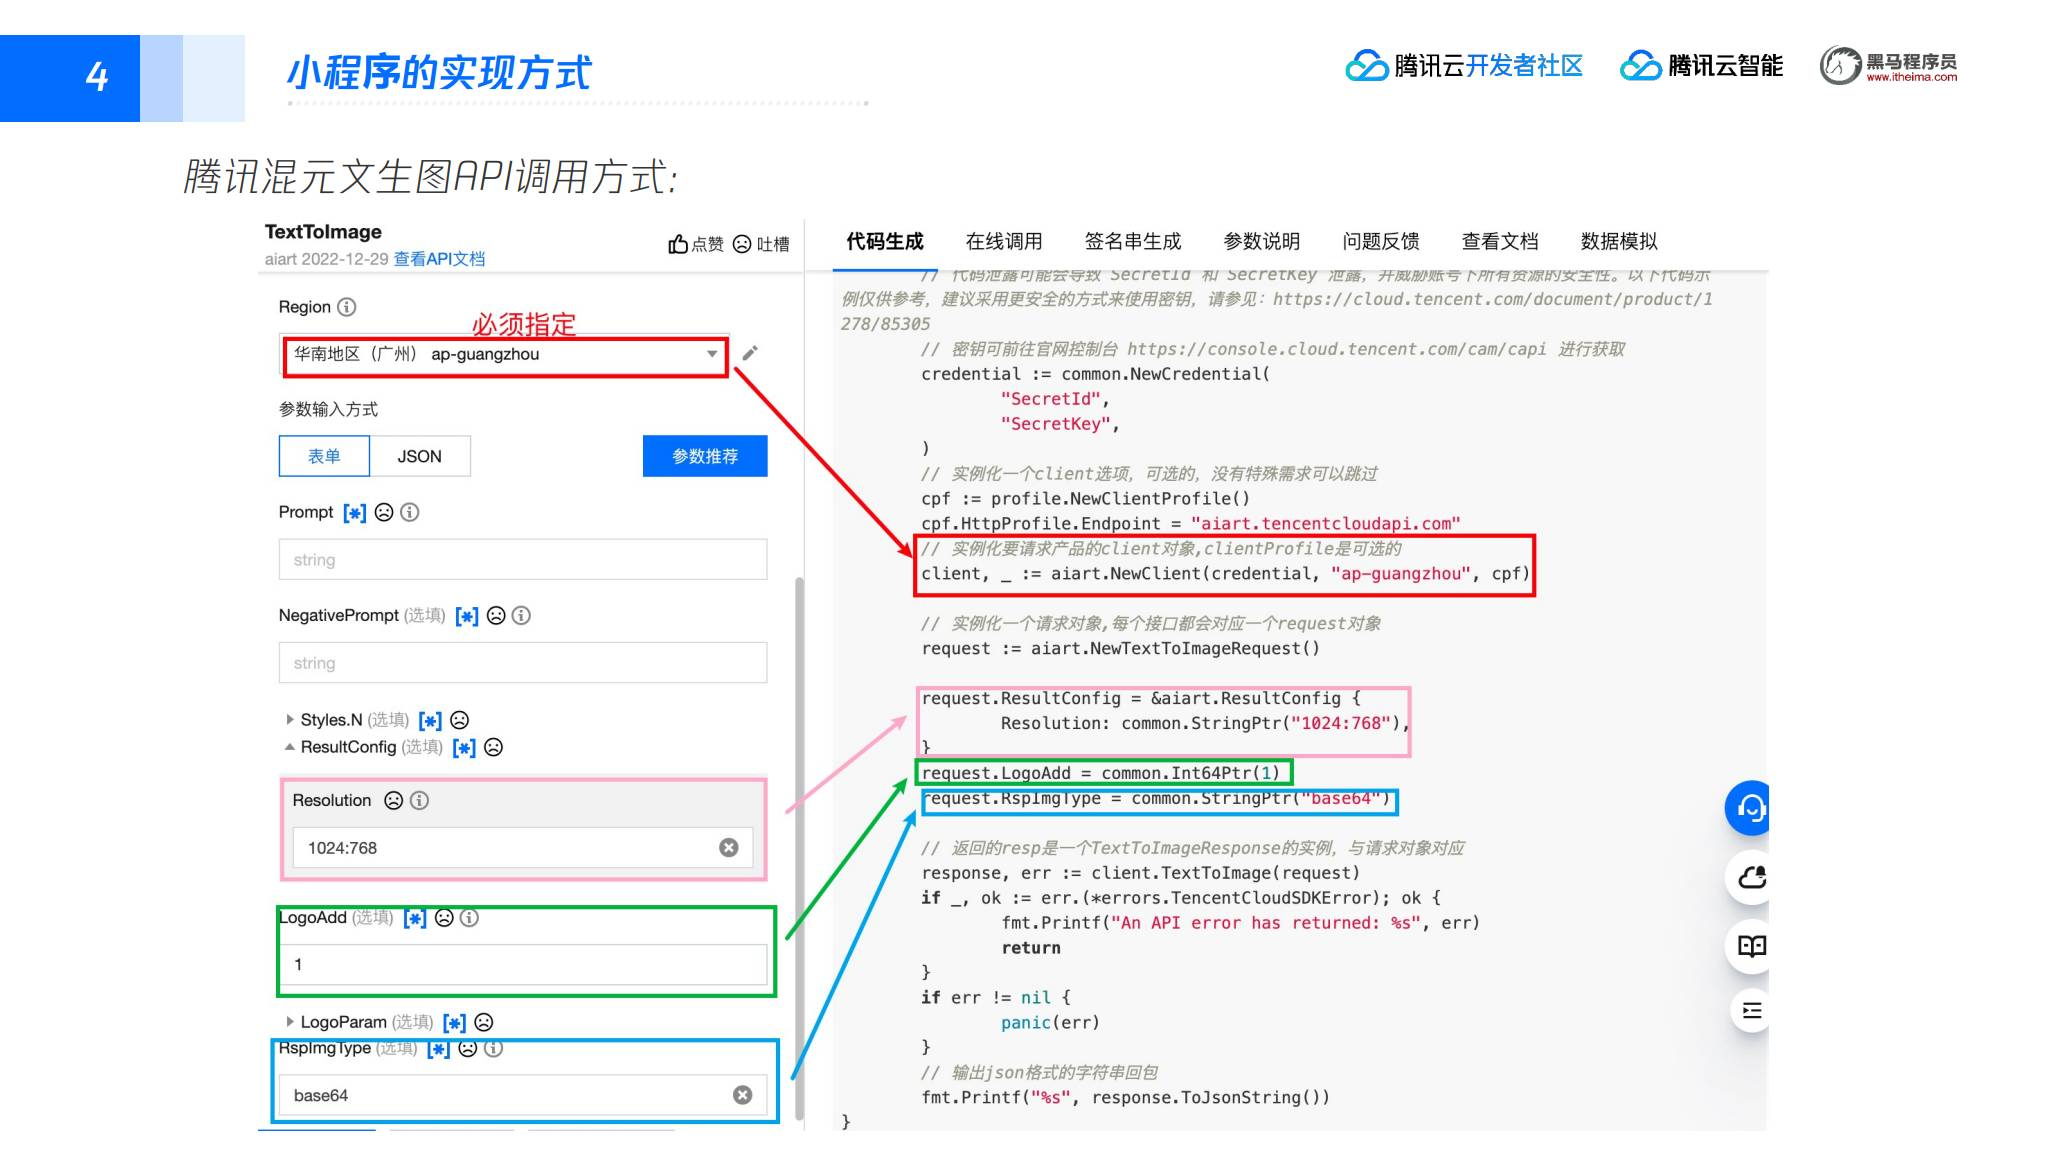

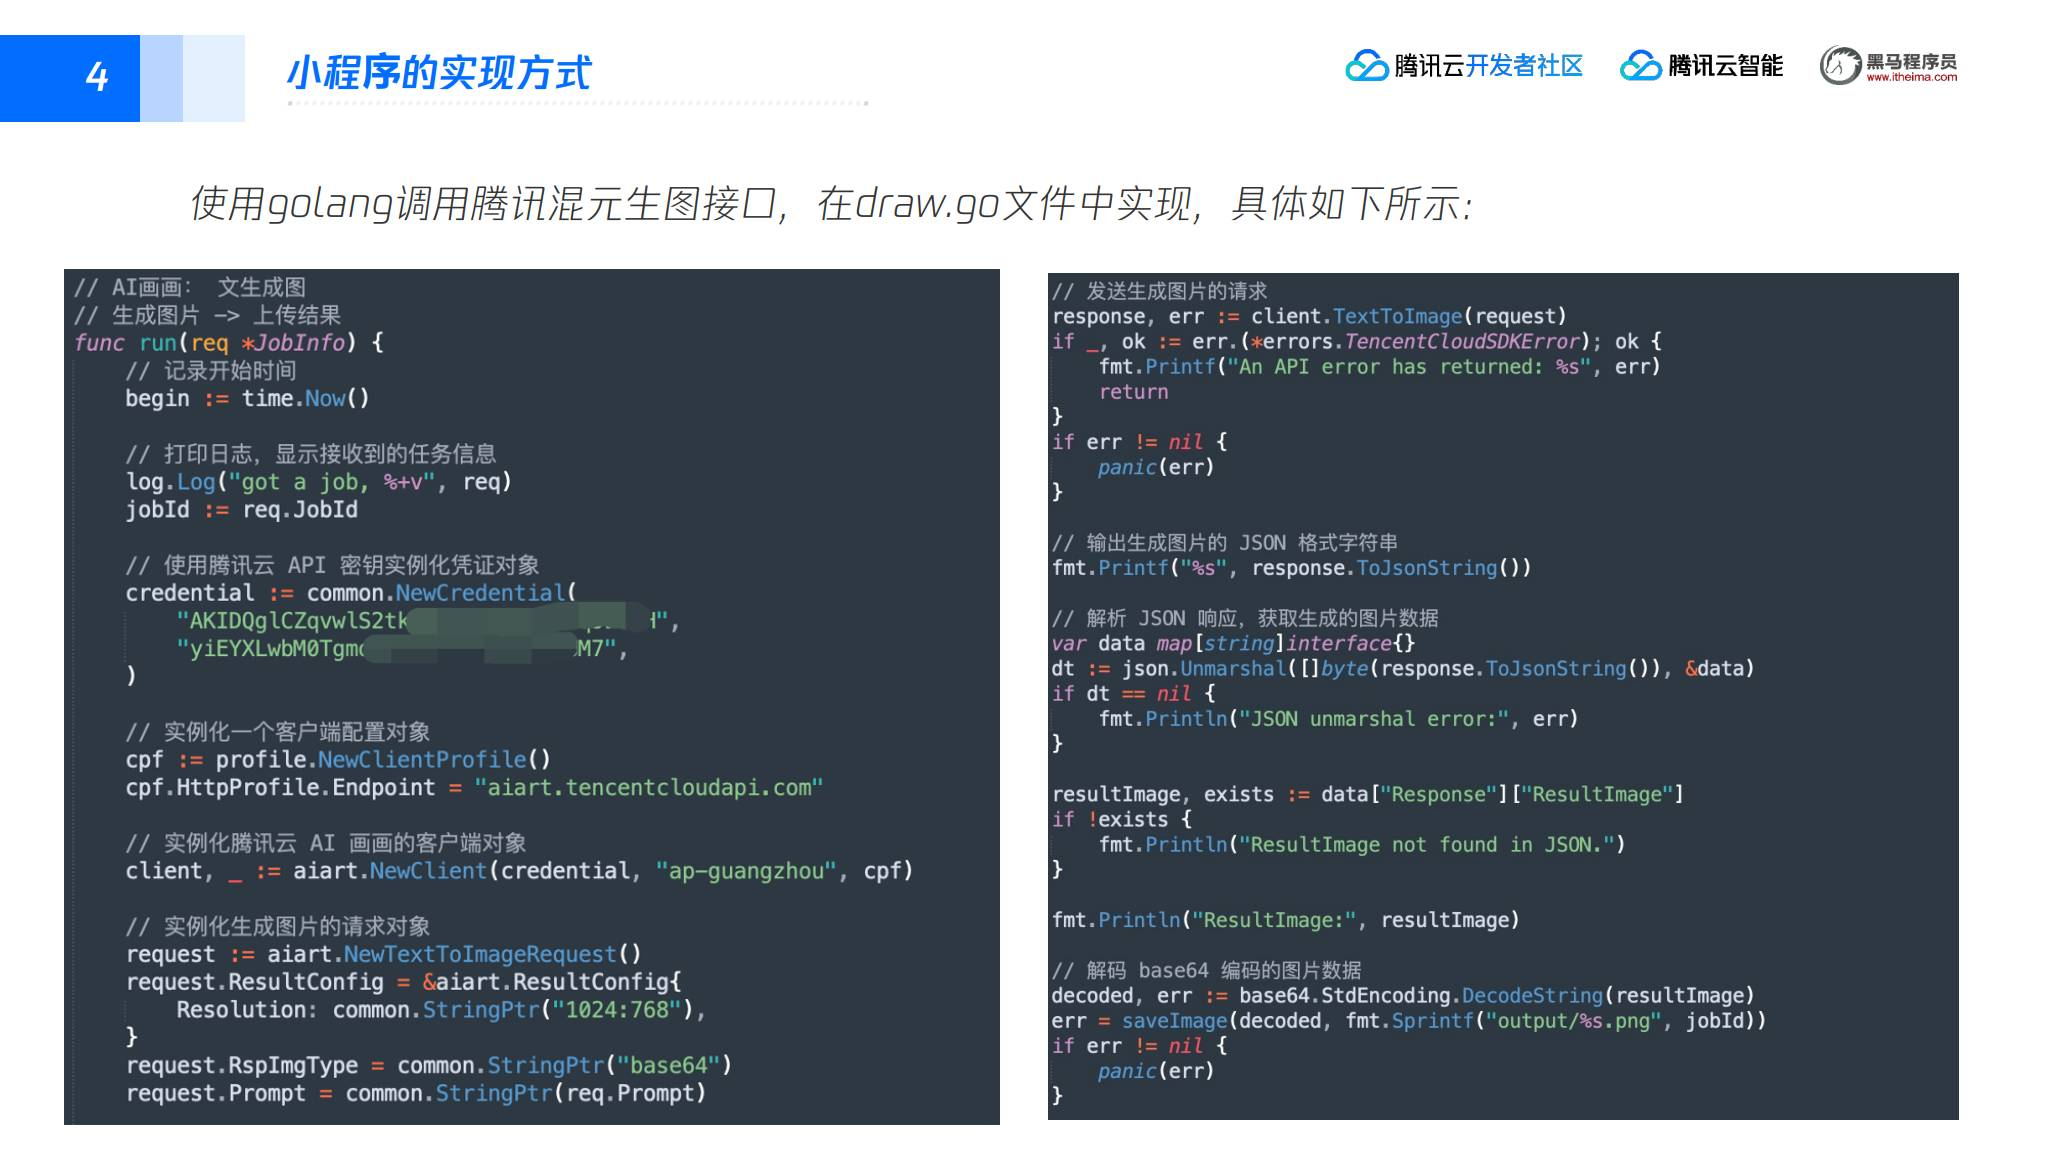

示例代码中的凭证字段使用了显式 `SecretId` 和 `SecretKey`。实际项目应改为环境变量或密钥管理服务，不要把真实凭证提交到 Git、前端包或日志中。响应数据包含图片的 base64 内容时，解码后才能写成 PNG 文件；如果接口配置返回 URL，则应按对应返回类型处理。

### 4. COS 上传和结果返回

腾讯云接口调用完成后，服务端执行两步：

- 从本地 `output/<jobId>.png` 读取生成图片；
- 调用 COS `PutObject` 上传到类似 `aidraw/<jobId>.png` 的对象路径；
- 通过 COS 预签名地址或业务服务地址返回可访问结果。

课件的响应结构包含：`SessionId`、`JobId`、`JobStatus`、`CostTime` 和 `ResultUrl` 等字段。

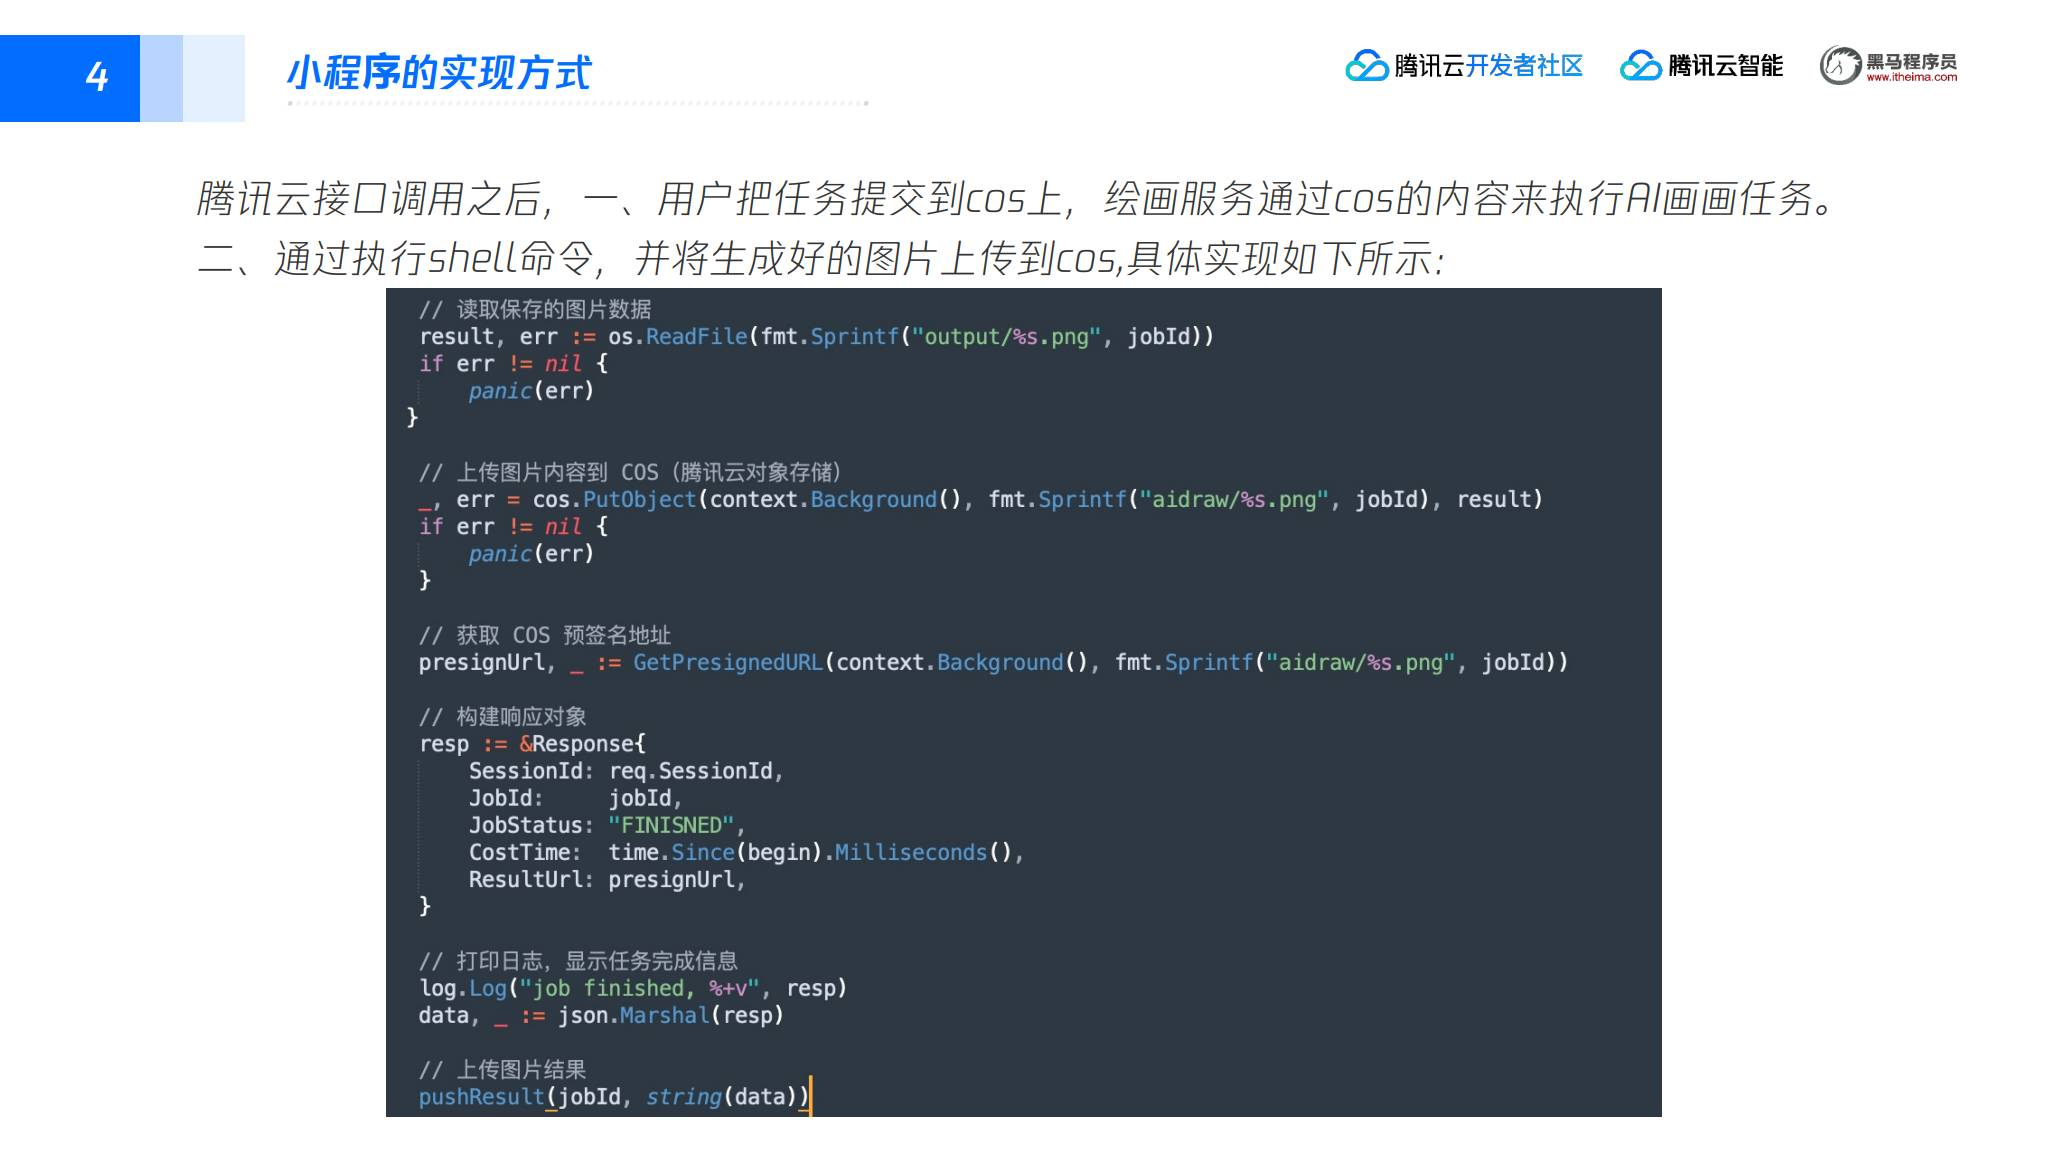

### 5. 用 COS 管理异步任务

`job.go` 负责任务的异步管理，课件列出的功能包括：

- 生成随机字符串和任务 ID；
- 推送任务；
- 拉取任务；
- 查询任务结果；
- 推送任务结果。

示例常量把任务队列和结果队列区分为 `aigc`、`aigcresult`。任务信息包含 `JobId` 和请求体；请求结构还包括 `SessionId`、`Prompt`、`ModelUrl`、`ImageUrl` 等字段。

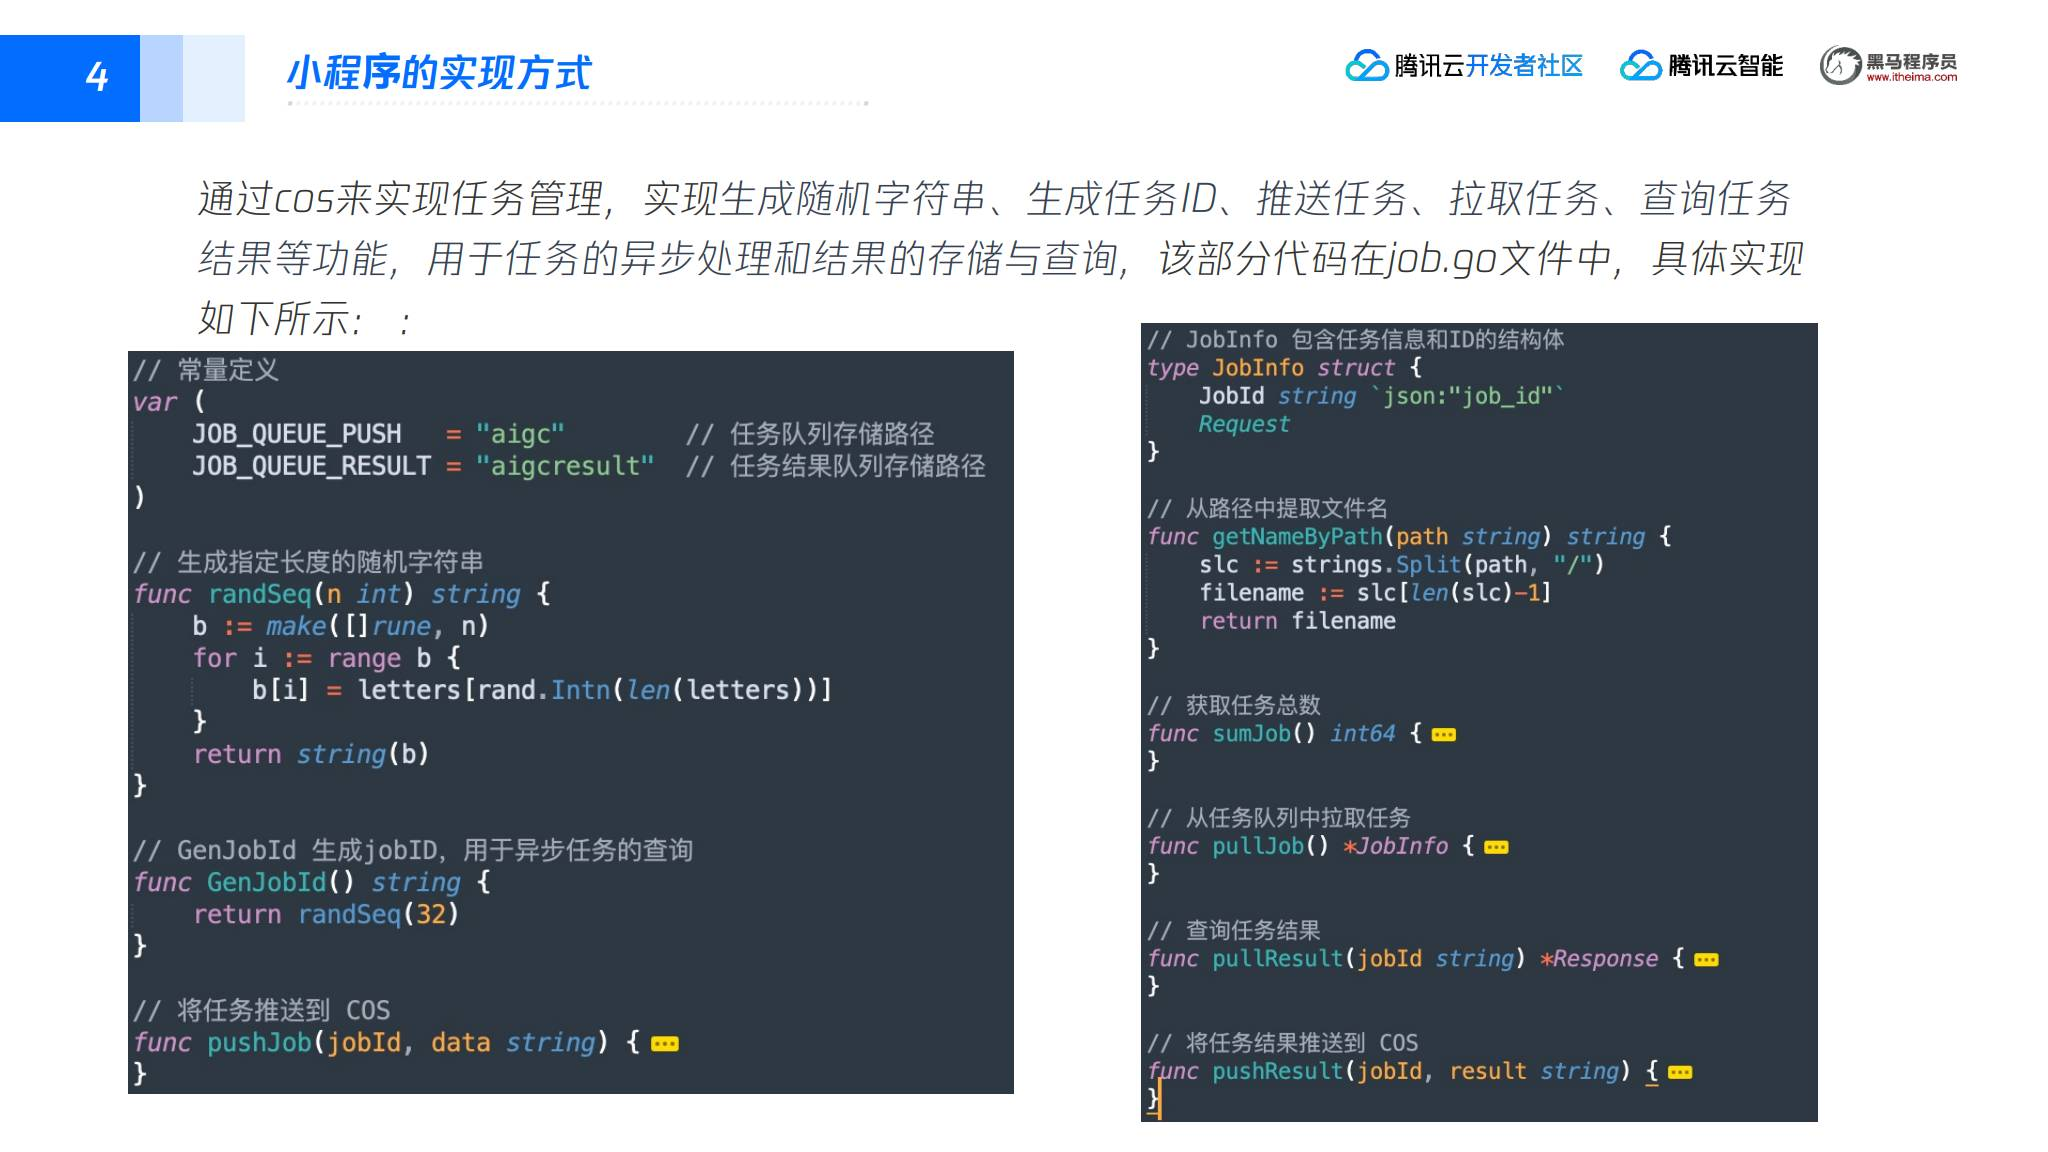

### 6. 中转服务与路由

`main.go` 负责启动 HTTP 服务和注册路由：

- `POST /frontend/create`：小程序提交任务；
- `POST /frontend/query`：小程序查询任务；
- `POST /aigc/create`：绘画服务调用混元生图。

程序通过命令行参数控制是否启动 AI 绘画工作循环：`-w=true` 时开启绘画服务端；否则只提供小程序服务端接口。

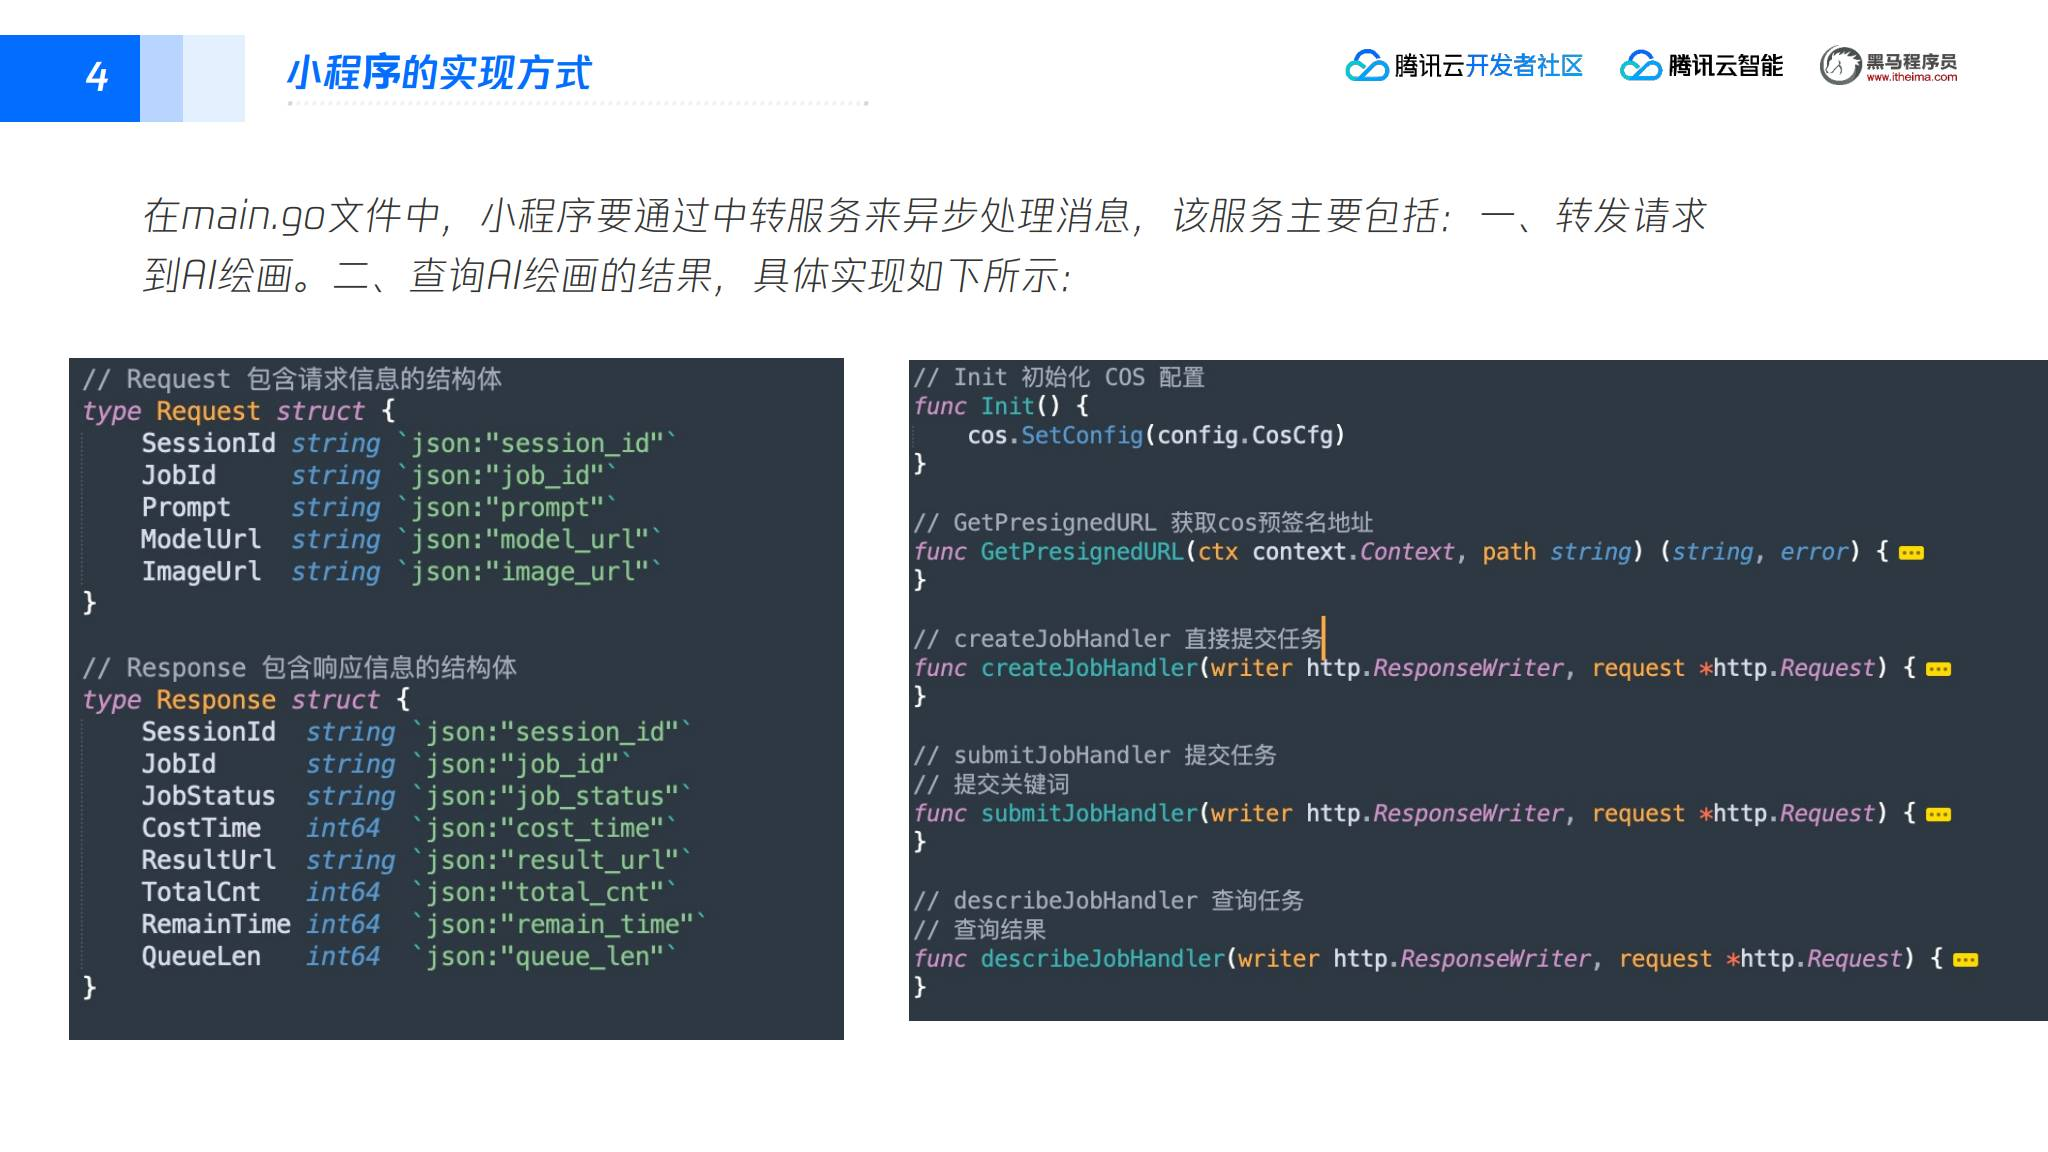

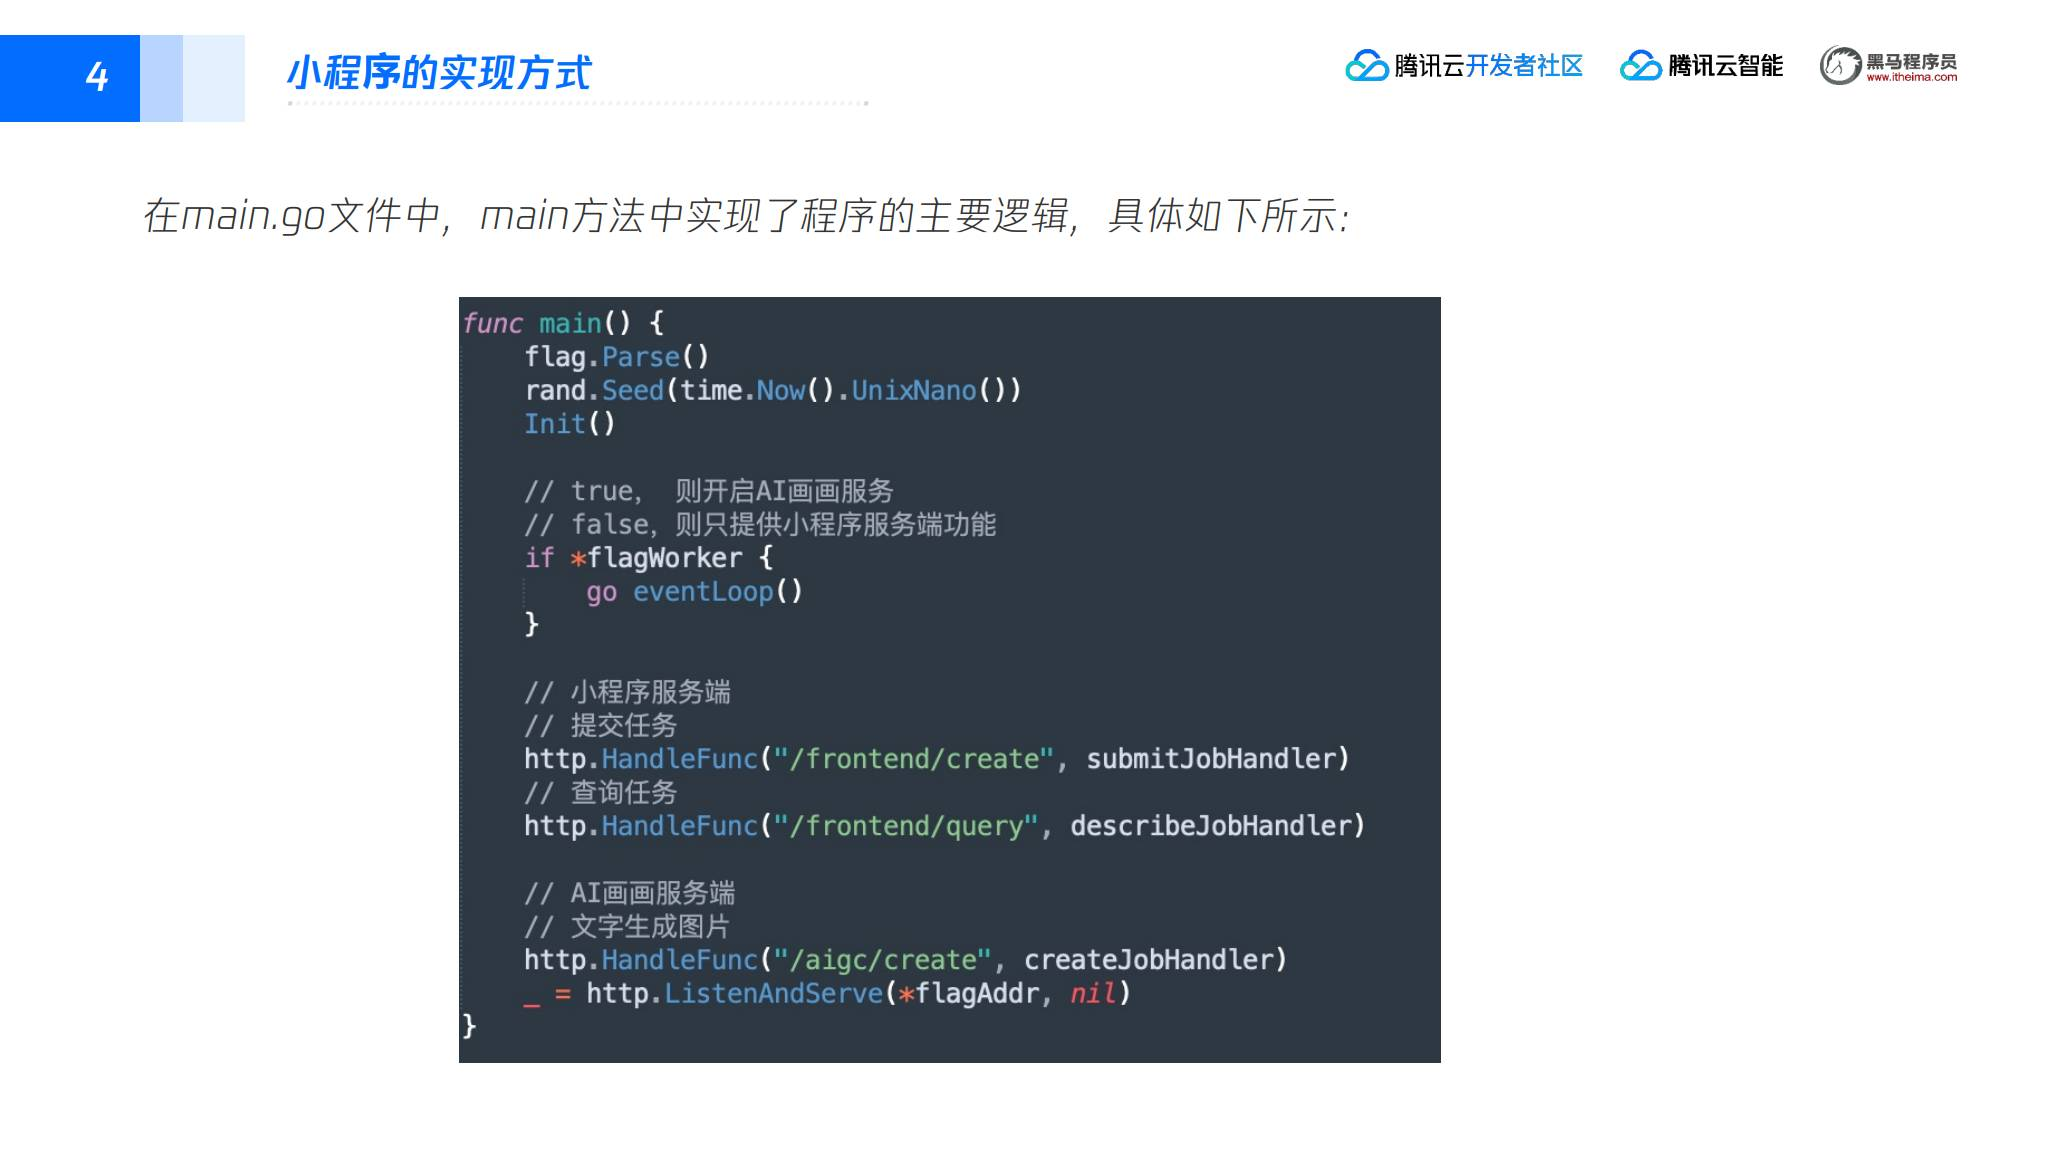

### 7. 小程序页面逻辑

`index.js` 负责页面数据、事件处理、用户信息、定时器、发起生成请求和在 Canvas 中绘制结果。任务提交后，小程序根据状态查询结果，并更新完成数量、处理时间和剩余时间。

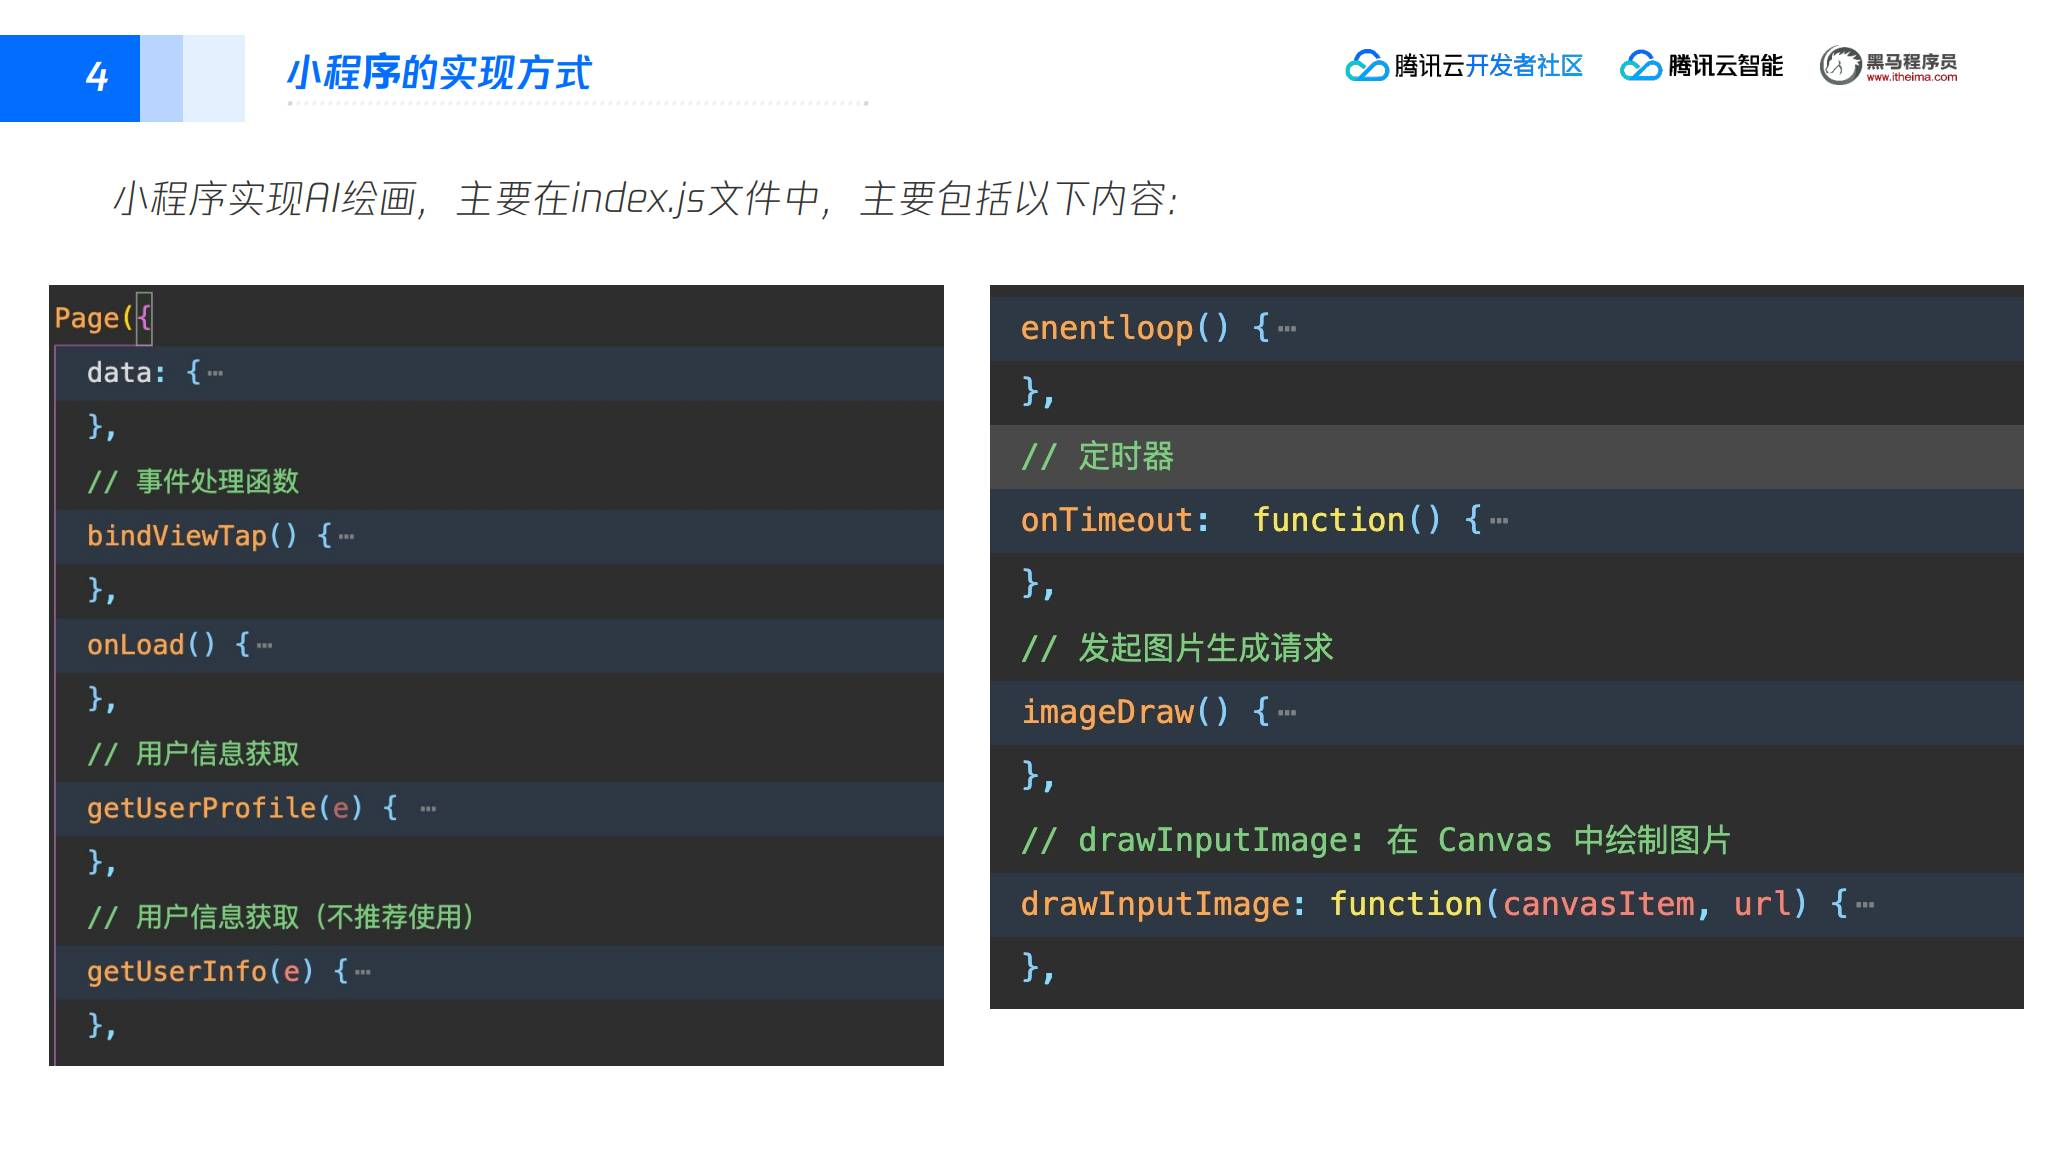

`index.wxml` 提供一个简单的图像生成界面：

- 输入框 placeholder 为“写下你的创意”，最大长度为 1024；
- 点击“立即生成”按钮触发 `handlerSearch`；
- 页面展示任务状态、完成数量、处理时间和剩余时间；
- 生成图片显示在页面中。

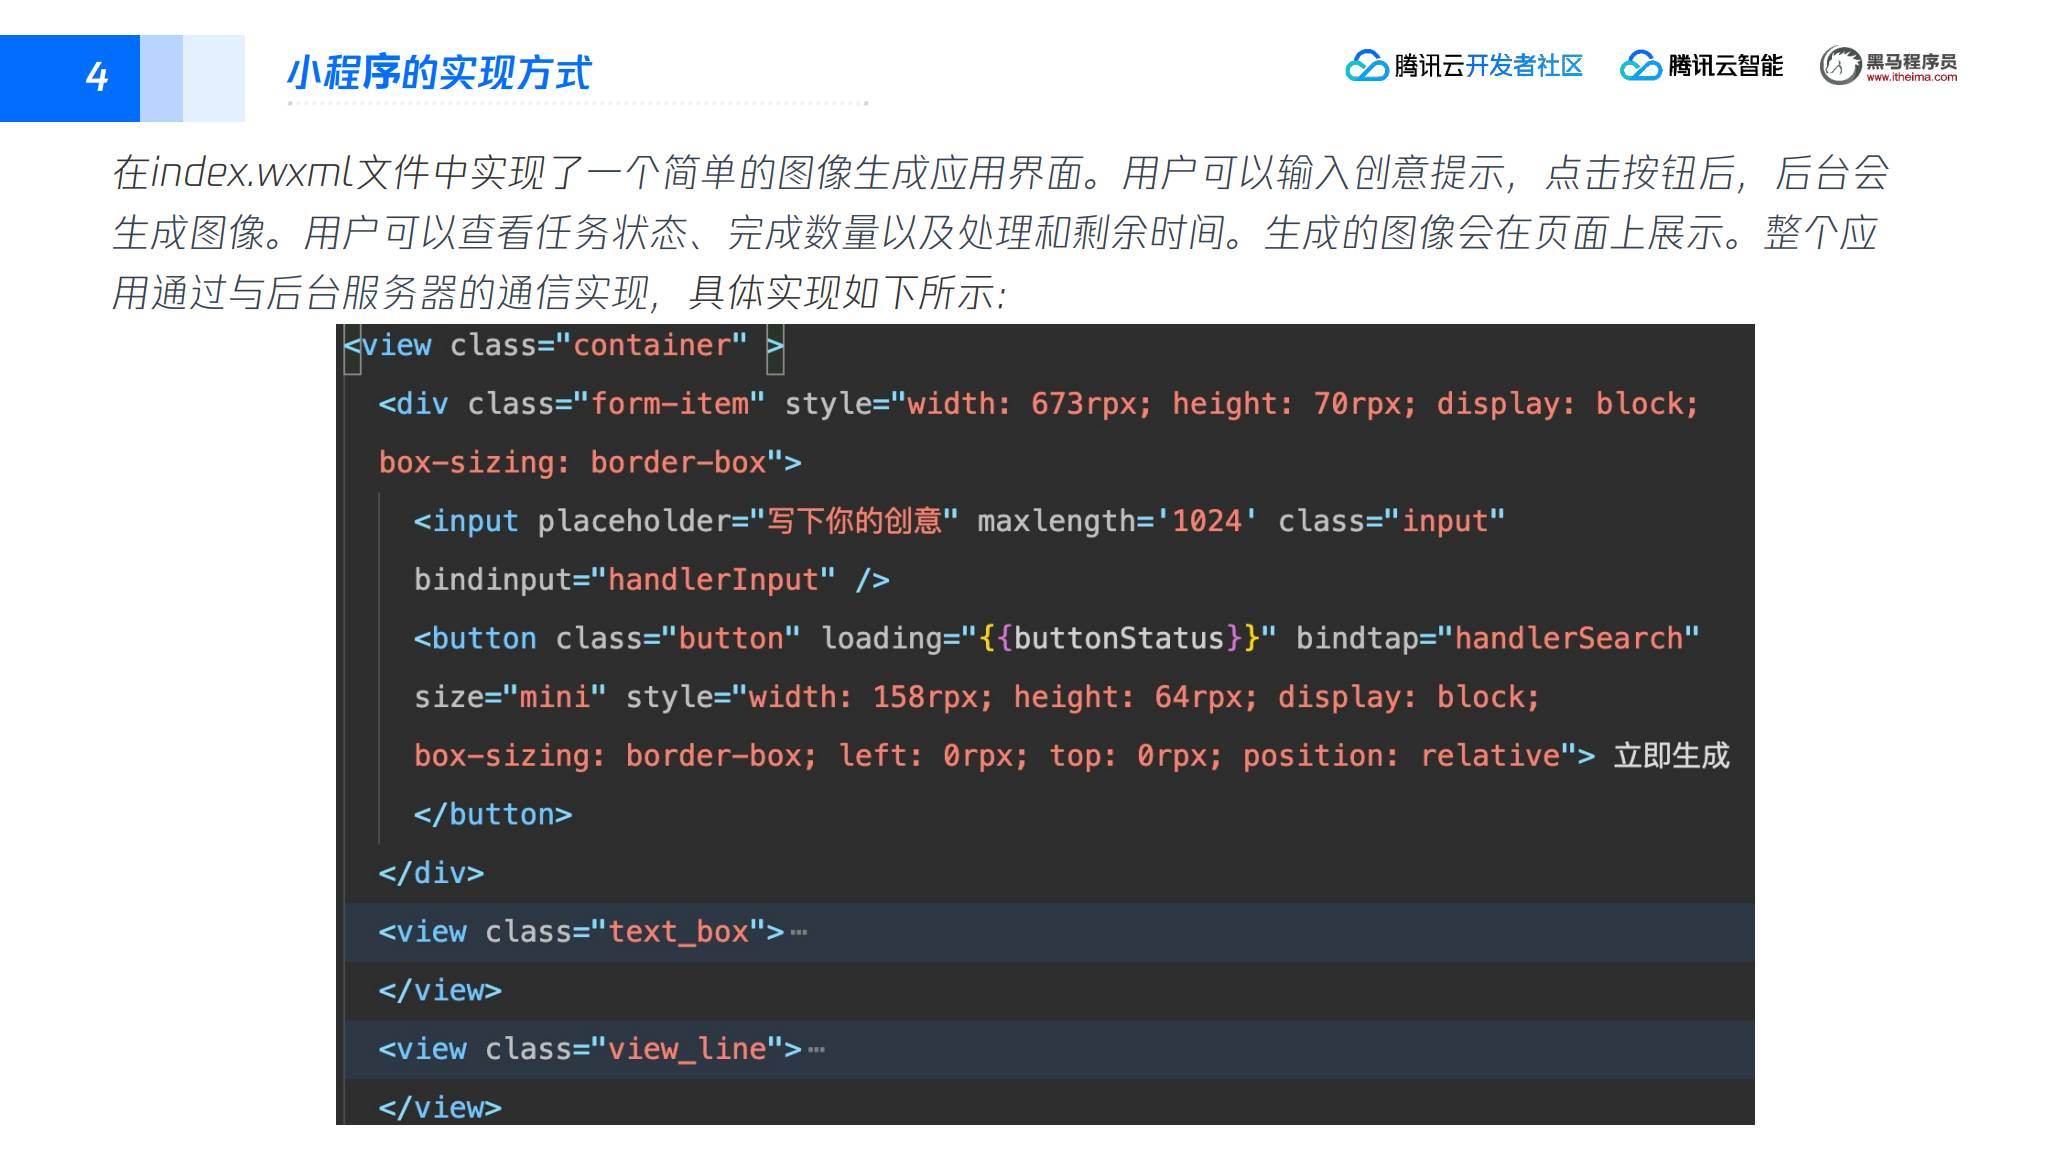

## 五、项目运行

在终端中进入服务端目录并编译：

```bash
cd drawserver
go build .
```

`go build .` 编译当前目录的 Go 源文件并生成可执行文件。启动小程序服务端和 AI 绘画服务：

```bash
./drawserver -w=true
```

启动前需要完成腾讯云凭证、COS 配置、API 地域和服务端地址配置；课件截图只展示流程，不包含可直接使用的账号信息。

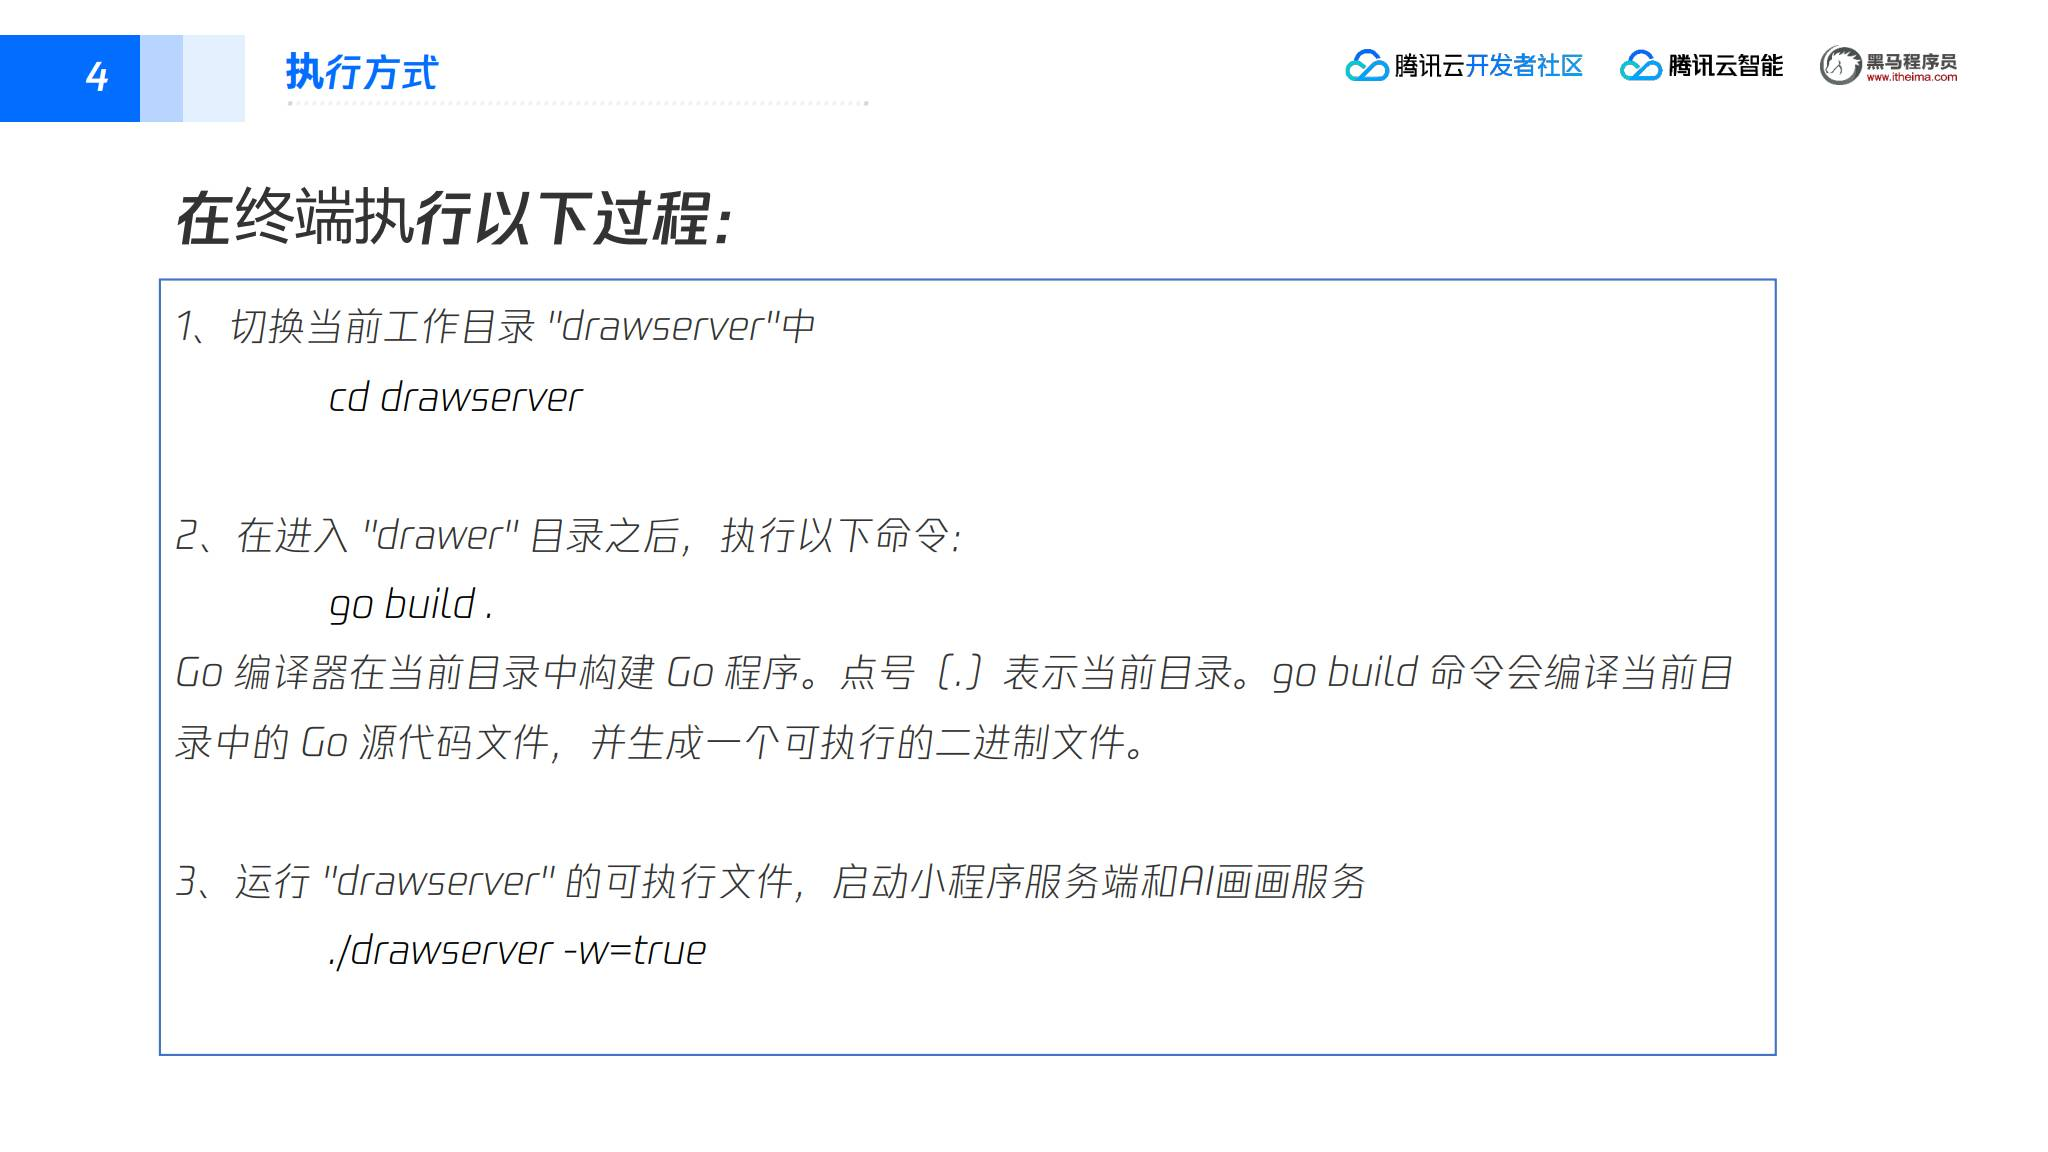

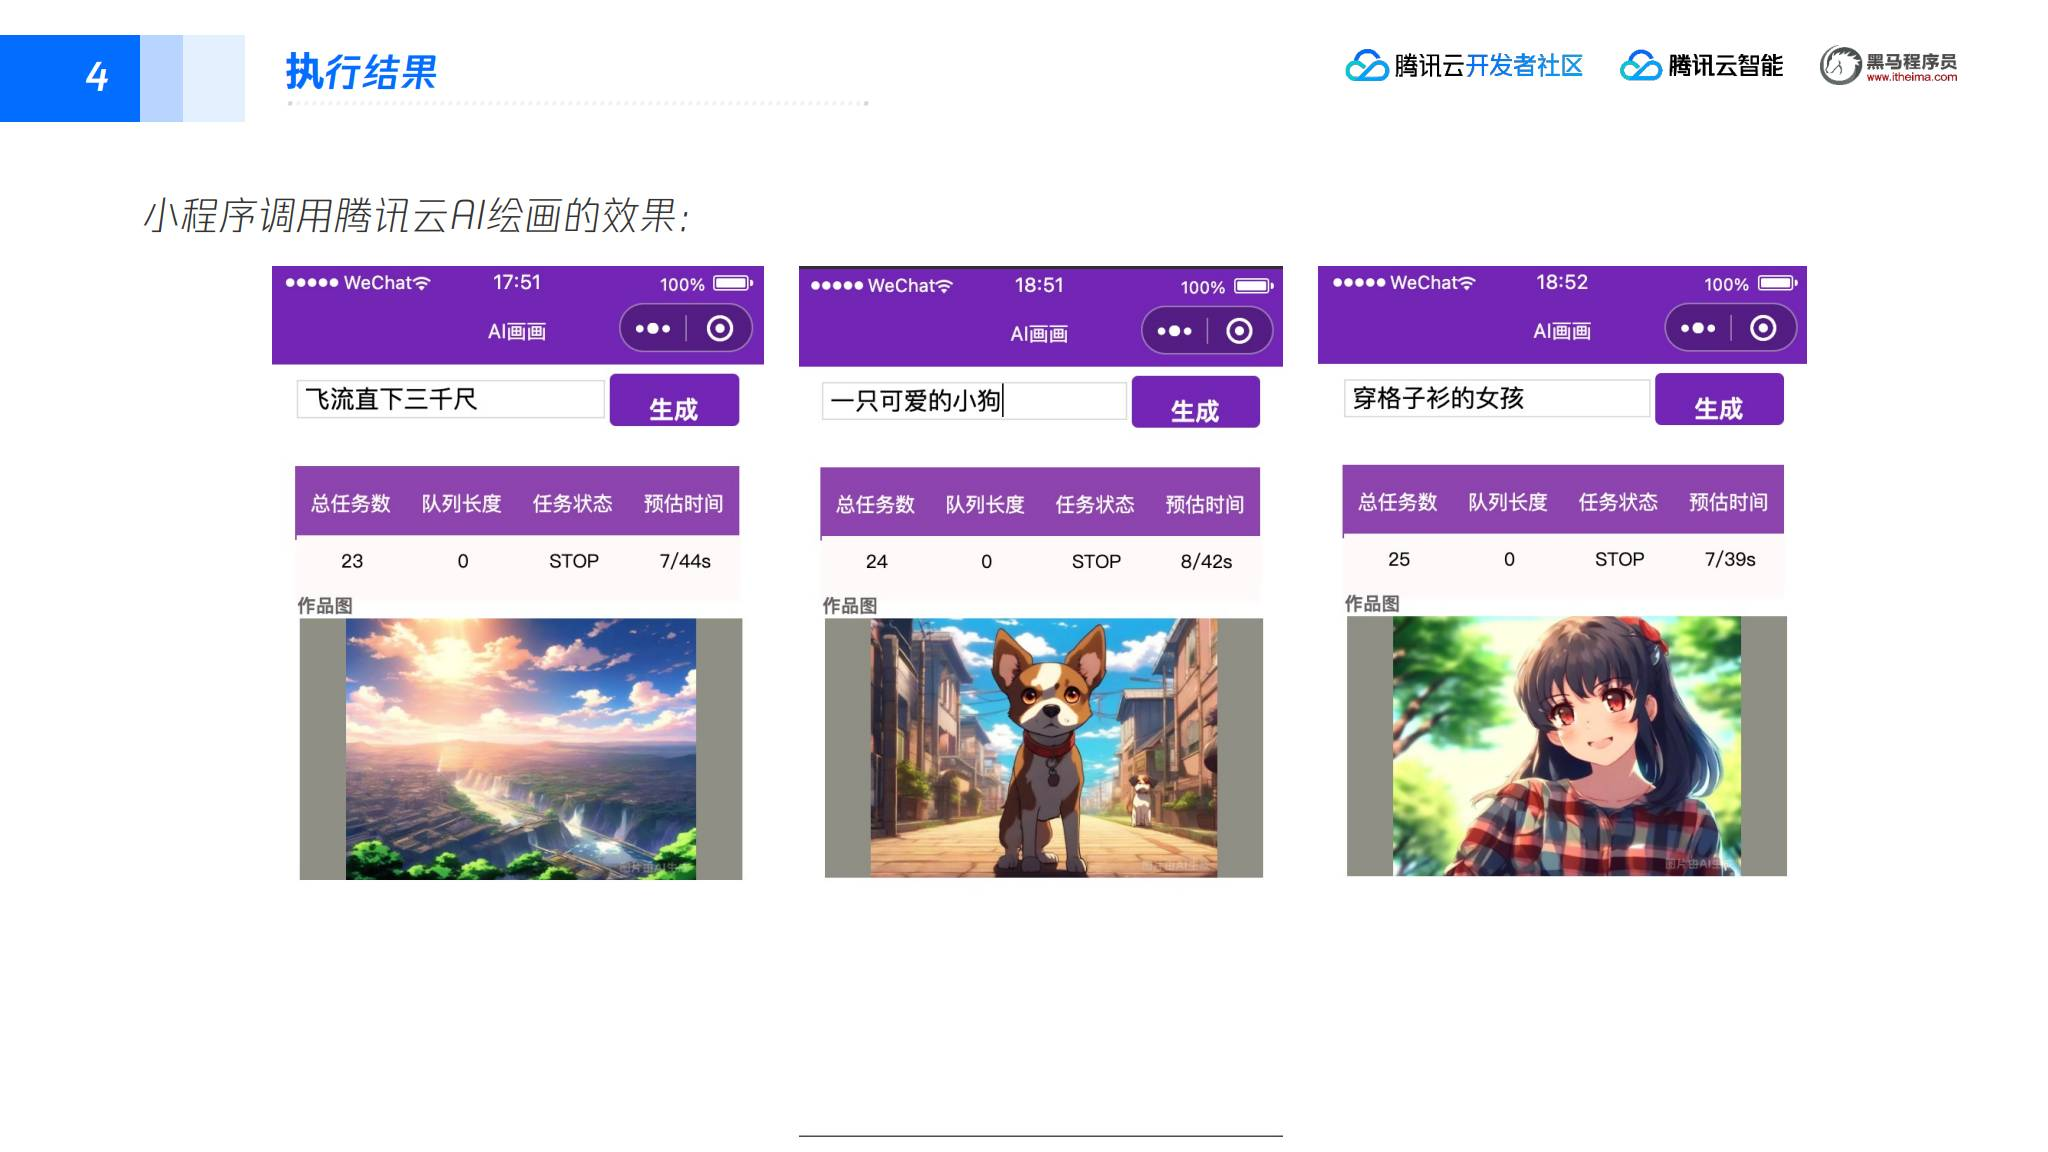

## 六、本篇要点

1. 腾讯混元生图同时提供 API 和 SaaS 两种形态，API 适合嵌入业务，SaaS 适合直接在线创作。
2. 文生图接口使用 `TextToImage`，输入描述性文本和风格参数，响应中包含图片结果和请求标识。
3. 小程序不应直接暴露云端密钥，应通过服务端中转和异步任务管理调用 API。
4. COS 既保存待处理任务，也保存生成图片和任务结果；`job.go` 负责任务 ID、队列和结果查询。
5. 服务端通过 `/frontend/create`、`/frontend/query` 和 `/aigc/create` 连接小程序与 AI 绘画服务，前端通过轮询或查询展示生成进度。
6. 项目启动顺序是进入 `drawserver`、执行 `go build .`，再运行 `./drawserver -w=true`。